In [ ]:
import torch
import os
from torch import nn
from torch.utils.data import DataLoader,random_split,Subset
from torchvision import datasets, transforms,models
import matplotlib.pyplot as plt
import torch.optim as optim
import numpy as np
from tqdm import tqdm
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import pandas as pd
import random

In [ ]:
def set_seed(seed=42):
  random.seed(seed)
  np.random.seed(seed)
  torch.manual_seed(seed)
  torch.cuda.manual_seed(seed)
  torch.cuda.manual_seed_all(seed)
  torch.backends.cudnn.deterministic=True
  torch.backends.cudnn.benchmark=False
set_seed(42)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("praveenkottari/bd3-dataset-for-building-defect-detection")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/praveenkottari/bd3-dataset-for-building-defect-detection/versions/1


In [ ]:
train_transforms=transforms.Compose([
    transforms.Resize((224,224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.2),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),
        scale=(0.9, 1.1)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    ),
    transforms.RandomErasing(p=0.3)
])

val_transform=transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [ ]:
path=os.path.join(path,"BD3_original_dataset/train")
dataset_no_transform=datasets.ImageFolder(path)
indices=list(range(len(dataset_no_transform)))
np.random.shuffle(indices)
total_size=len(dataset_no_transform)
train_size=int(0.7*total_size)
val_size=int(0.15*total_size)
test_size=total_size-train_size-val_size
train_idx=indices[:train_size]
val_idx=indices[train_size:train_size+val_size]
test_idx=indices[train_size+val_size:]

# Define the custom class FIRST
class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, dataset, indices, transform=None):
        self.dataset = dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img_path, label = self.dataset.samples[self.indices[idx]]
        img = datasets.folder.default_loader(img_path)
        if self.transform:
            img = self.transform(img)
        return img, label

# THEN create the datasets with proper transforms
train_dataset = TransformSubset(dataset_no_transform, train_idx, train_transforms)
val_dataset = TransformSubset(dataset_no_transform, val_idx, val_transform)
test_dataset = TransformSubset(dataset_no_transform, test_idx, val_transform)

num_classes = len(dataset_no_transform.classes)
class_names = dataset_no_transform.classes

print(len(train_dataset), len(val_dataset), len(test_dataset),len(dataset_no_transform),
      class_names,num_classes
      )

2775 594 596 3965 ['algae', 'major_crack', 'minor_crack', 'peeling', 'plain', 'spalling', 'stain'] 7


In [ ]:
batch_size=32
num_workers=2
learning_rate=0.001

In [ ]:
def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

In [ ]:
train_loader=DataLoader(train_dataset,
                        batch_size=batch_size,
                        shuffle=True,
                        num_workers=num_workers,
                        worker_init_fn=seed_worker,
                        generator=torch.Generator().manual_seed(42),
                        pin_memory=True)

val_loader=DataLoader(val_dataset,
                        batch_size=batch_size,
                        shuffle=False,
                        num_workers=num_workers,
                        worker_init_fn=seed_worker,
                        generator=torch.Generator().manual_seed(42),
                        pin_memory=True)

test_loader=DataLoader(test_dataset,
                        batch_size=batch_size,
                        shuffle=False,
                        num_workers=num_workers,
                        worker_init_fn=seed_worker,
                        generator=torch.Generator().manual_seed(42),
                        pin_memory=True)


In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ============================================================================
# MODEL FACTORY - WITH DROPOUT FOR REGULARIZATION
# ============================================================================
def get_model(model_name, num_classes, dropout=0.3):
    """Create different models with dropout for regularization"""

    if model_name == 'resnet18':
        model = models.resnet18(pretrained=True)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'resnet34':
        model = models.resnet34(pretrained=True)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'resnet50':
        model = models.resnet50(pretrained=True)
        num_features = model.fc.in_features
        model.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'efficientnet_b0':
        model = models.efficientnet_b0(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'efficientnet_b1':
        model = models.efficientnet_b1(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'efficientnet_b2':
        model = models.efficientnet_b2(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'efficientnet_b3':
        model = models.efficientnet_b3(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'efficientnet_b4':
        model = models.efficientnet_b4(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    # EfficientNet V2 (Newer, better versions - recommended!)
    elif model_name == 'efficientnet_v2_s':
        model = models.efficientnet_v2_s(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'efficientnet_v2_m':
        model = models.efficientnet_v2_m(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'efficientnet_v2_l':
        model = models.efficientnet_v2_l(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'densenet121':
        model = models.densenet121(pretrained=True)
        num_features = model.classifier.in_features
        model.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, num_classes)
        )

    elif model_name == 'mobilenet_v2':
        model = models.mobilenet_v2(pretrained=True)
        num_features = model.classifier[1].in_features
        model.classifier = nn.Sequential(
            nn.Dropout(p=dropout, inplace=True),
            nn.Linear(num_features, num_classes)
        )

    else:
        raise ValueError(f"Model {model_name} not supported")

    return model

In [ ]:
from types import LambdaType
def train_one_epoch(model,train_loader,criterion,optimizer,device):
    model.train()
    running_loss=0.0
    correct=0
    total=0
    pbar=tqdm(train_loader,desc="Training")
    for images,labels in pbar:
      images,labels=images.to(device),labels.to(device)
      optimizer.zero_grad()
      outputs=model(images)
      loss=criterion(outputs,labels)
      loss.backward()
      optimizer.step()

      running_loss+=loss.item()*images.size(0)
      _,predicted=torch.max(outputs.data,1)
      correct+=(predicted==labels).sum().item()
      total+=labels.size(0)
      pbar.set_postfix({'loss':loss.item(), 'acc':100*correct/total})


    epoch_loss=running_loss/total
    epoch_acc=100*correct/total
    return epoch_loss,epoch_acc



In [ ]:
def validate(model,val_loader,criterion,device):
  model.eval()
  running_loss=0.0
  correct=0
  total=0
  with torch.no_grad():
    pbar=tqdm(val_loader,desc="Validation")
    for images,Labels in pbar:
      images,labels=images.to(device),Labels.to(device)
      outputs=model(images)
      loss=criterion(outputs,labels)
      running_loss+=loss.item()*images.size(0)
      _,predicted=torch.max(outputs.data,1)
      correct+=(predicted==labels).sum().item()
      total+=labels.size(0)
      pbar.set_postfix({'loss':loss.item(), 'acc':100*correct/total})

  epoch_loss=running_loss/total
  epoch_acc=100*correct/total
  return epoch_loss,epoch_acc

In [ ]:
def train_single_model(model_name, train_loader, val_loader, test_loader,
                       num_classes, class_names, device):
    """
    Train a single model and return results
    """
    print(f"\n{'='*70}")
    print(f"TRAINING MODEL: {model_name.upper()}")
    print(f"{'='*70}\n")

    # Create model
    model = get_model(model_name, num_classes,dropout=0.3)
    model = model.to(device)

    # Count parameters
    total_params = sum(p.numel() for p in model.parameters())
    print(f"Total parameters: {total_params:,}\n")

    # Setup training
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=3
    )

    # Training settings
    num_epochs = 30
    best_val_acc = 0.0
    history = {
        'train_loss': [],
        'train_acc': [],
        'val_loss': [],
        'val_acc': []
    }
    patience=7
    patience_counter=0

    # Training loop
    for epoch in range(num_epochs):
        print(f"\nEpoch [{epoch + 1}/{num_epochs}]")
        print("-" * 70)

        # Train
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)

        # Validate
        val_loss, val_acc = validate(model, val_loader, criterion, device)

        # Update learning rate
        scheduler.step(val_loss)

        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        # Print epoch summary
        print(f"\nEpoch Summary:")
        print(f"  Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}%")
        print(f"  Val Loss:   {val_loss:.4f} | Val Acc:   {val_acc:.2f}%")

        # Save best model
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter=0
            torch.save(model.state_dict(), f'best_{model_name}.pth')
            print(f"  ✓ New best model saved! (Val Acc: {val_acc:.2f}%)")
        else:
            patience_counter+=1

        if patience_counter>=patience:
            print(f"  ✓ Early stopping triggered!{epoch+1}")
            break

    # Evaluate on test set
    print(f"\n{'='*70}")
    print(f"EVALUATING {model_name.upper()} ON TEST SET")
    print(f"{'='*70}\n")

    model.load_state_dict(torch.load(f'best_{model_name}.pth'))
    test_acc, predictions, true_labels = evaluate_model_simple(model, test_loader, device)

    print(f"Test Accuracy: {test_acc:.2f}%")
    print(f"Best Val Accuracy: {best_val_acc:.2f}%\n")

    # Return results
    return {
        'model_name': model_name,
        'total_params': total_params,
        'best_val_acc': best_val_acc,
        'test_acc': test_acc,
        'history': history,
        'predictions': predictions,
        'true_labels': true_labels
    }

In [ ]:
def evaluate_model_simple(model, test_loader, device):
    """Evaluate model on test set"""
    model.eval()
    all_predictions = []
    all_labels = []
    correct = 0
    total = 0

    with torch.no_grad():
        pbar = tqdm(test_loader, desc='Testing')
        for images, labels in pbar:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)

            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    test_acc = 100 * correct / total
    return test_acc, all_predictions, all_labels

In [ ]:
models_to_train = [
   'efficientnet_b0',
    'resnet18',
    'efficientnet_v2_s',
    'densenet121',
    'mobilenet_v2'



]

# To train only ONE model, use:
# models_to_train = ['efficientnet_b0']

# To train ALL available models, use:
# models_to_train = ['resnet18', 'resnet34', 'resnet50', 'efficientnet_b0',
#                    'densenet121', 'mobilenet_v2']


print(f"\n{'='*70}")
print(f"WILL TRAIN {len(models_to_train)} MODELS:")
print(f"{'='*70}")
for i, model_name in enumerate(models_to_train, 1):
    print(f"{i}. {model_name}")
print(f"{'='*70}\n")

# Train all models
all_results = {}

for model_name in models_to_train:
    results = train_single_model(
        model_name,
        train_loader,
        val_loader,
        test_loader,
        num_classes,
        class_names,
        device
    )
    all_results[model_name] = results

    # Print summary after each model
    print(f"\n{'─'*70}")
    print(f"✓ {model_name} completed!")
    print(f"  Parameters: {results['total_params']:,}")
    print(f"  Best Val Acc: {results['best_val_acc']:.2f}%")
    print(f"  Test Acc: {results['test_acc']:.2f}%")
    print(f"{'─'*70}\n")


WILL TRAIN 5 MODELS:
1. efficientnet_b0
2. resnet18
3. efficientnet_v2_s
4. densenet121
5. mobilenet_v2


TRAINING MODEL: EFFICIENTNET_B0

Total parameters: 4,016,515


Epoch [1/30]
----------------------------------------------------------------------


Validation: 100%|██████████| 19/19 [00:02<00:00,  7.31it/s, loss=0.356, acc=86.9]



Epoch Summary:
  Train Loss: 0.8178 | Train Acc: 72.50%
  Val Loss:   0.3780 | Val Acc:   86.87%
  ✓ New best model saved! (Val Acc: 86.87%)

Epoch [2/30]
----------------------------------------------------------------------


Validation: 100%|██████████| 19/19 [00:03<00:00,  5.80it/s, loss=0.0705, acc=88.7]



Epoch Summary:
  Train Loss: 0.4886 | Train Acc: 83.71%
  Val Loss:   0.3231 | Val Acc:   88.72%
  ✓ New best model saved! (Val Acc: 88.72%)

Epoch [3/30]
----------------------------------------------------------------------


Validation: 100%|██████████| 19/19 [00:02<00:00,  7.02it/s, loss=0.162, acc=90.7]


... (227 outputs left out)

Validation: 100%|██████████| 19/19 [00:02<00:00,  7.35it/s, loss=0.0923, acc=93.1]



Epoch Summary:
  Train Loss: 0.1000 | Train Acc: 96.32%
  Val Loss:   0.2499 | Val Acc:   93.10%

EVALUATING MOBILENET_V2 ON TEST SET



Testing: 100%|██████████| 19/19 [00:02<00:00,  7.55it/s]

Test Accuracy: 91.78%
Best Val Accuracy: 93.94%


──────────────────────────────────────────────────────────────────────
✓ mobilenet_v2 completed!
  Parameters: 2,232,839
  Best Val Acc: 93.94%
  Test Acc: 91.78%
──────────────────────────────────────────────────────────────────────



In [ ]:
comparison_data = []
for model_name, results in all_results.items():
    comparison_data.append({
        'Model': model_name,
        'Parameters (M)': results['total_params'] / 1e6,
        'Best Val Acc (%)': results['best_val_acc'],
        'Test Acc (%)': results['test_acc']
    })

df = pd.DataFrame(comparison_data)
df = df.sort_values('Test Acc (%)', ascending=False)
print(df.to_string(index=False))

# Save comparison
df.to_csv('model_comparison.csv', index=False)
print("\n✓ Comparison saved to 'model_comparison.csv'")

# Find best model
best_model_name = df.iloc[0]['Model']
best_model_acc = df.iloc[0]['Test Acc (%)']

print(f"\n{'='*70}")
print(f"🏆 BEST MODEL: {best_model_name.upper()}")
print(f"   Test Accuracy: {best_model_acc:.2f}%")
print(f"{'='*70}\n")

            Model  Parameters (M)  Best Val Acc (%)  Test Acc (%)
  efficientnet_b0        4.016515         94.612795     93.456376
         resnet18       11.180103         93.097643     92.617450
     mobilenet_v2        2.232839         93.939394     91.778523
      densenet121        6.961031         91.414141     91.610738
efficientnet_v2_s       20.186455         93.434343     91.442953

✓ Comparison saved to 'model_comparison.csv'

🏆 BEST MODEL: EFFICIENTNET_B0
   Test Accuracy: 93.46%



###Add imports + style setup (add right after the last print statement)

In [ ]:
# --- Add these imports at top of new cell ---
from sklearn.metrics import (precision_recall_fscore_support, roc_curve, auc,
                              precision_recall_curve, average_precision_score)
from sklearn.preprocessing import label_binarize
import torch.nn.functional as F

# Research paper style
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 12,
    'axes.labelsize': 14,
    'axes.titlesize': 15,
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
COLORS = ['#2274A5', '#F75C03', '#D90368', '#00CC66', '#8B5CF6', '#F4A261']

###Dataset Distribution

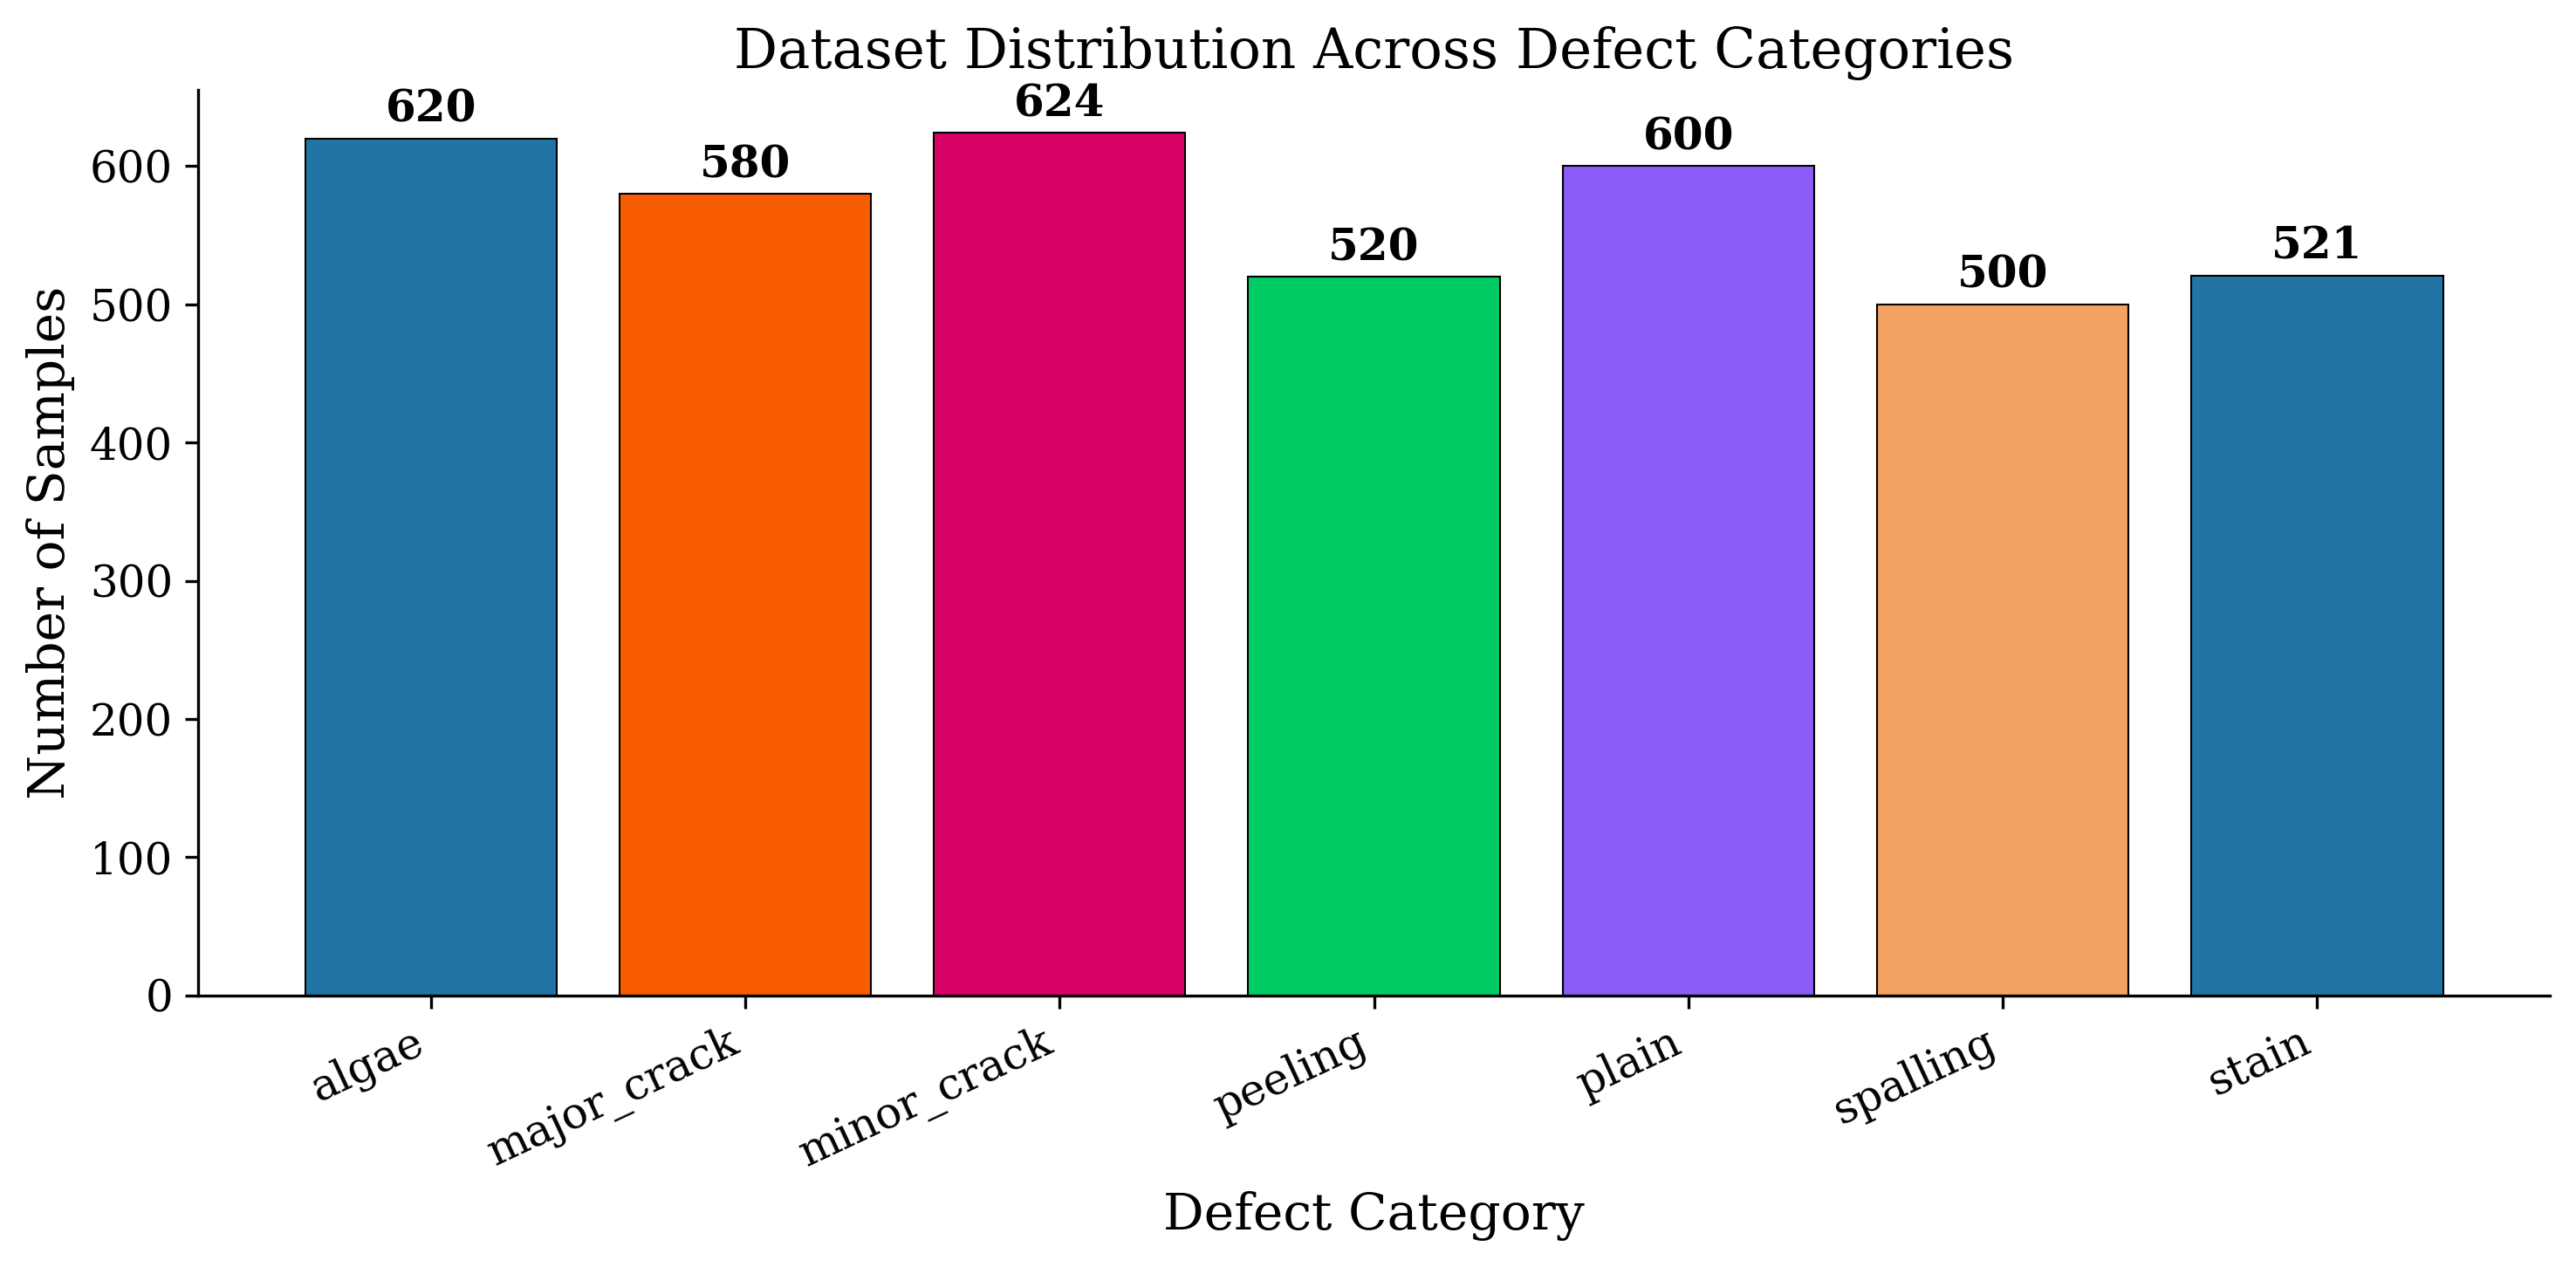

In [ ]:
labels_list = [dataset_no_transform.targets[i] for i in range(len(dataset_no_transform))]
class_counts = pd.Series(labels_list).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(class_names, class_counts.values, color=COLORS[:num_classes], edgecolor='black', linewidth=0.5)
for bar, count in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 5,
            str(count), ha='center', va='bottom', fontweight='bold')
ax.set_xlabel('Defect Category')
ax.set_ylabel('Number of Samples')
ax.set_title('Dataset Distribution Across Defect Categories')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('fig1_dataset_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

###Train/Val/Test Split per Class

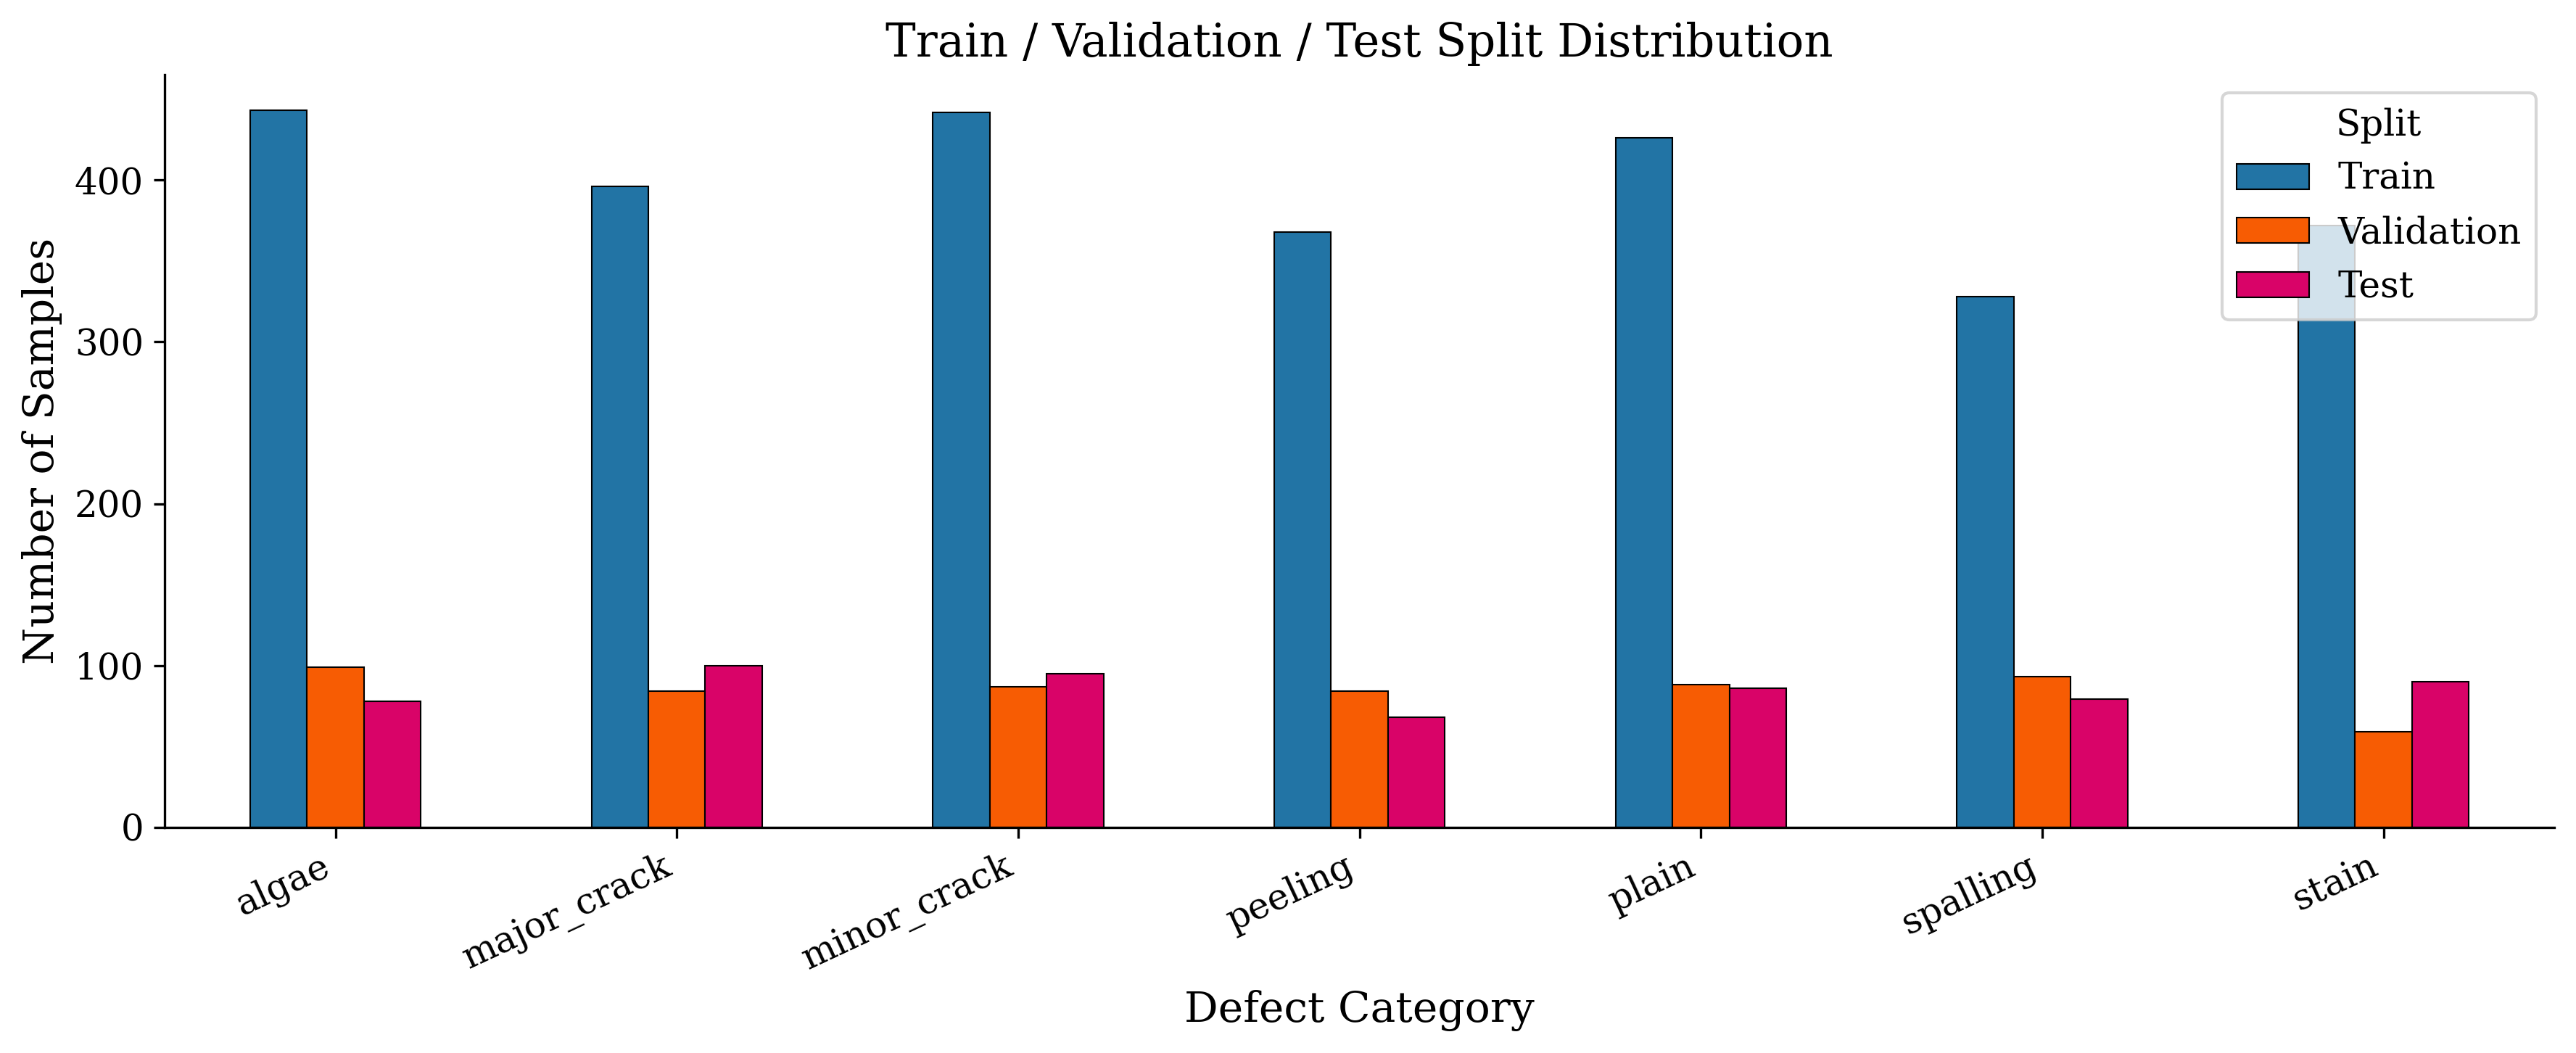

In [ ]:
train_labels = [dataset_no_transform.targets[i] for i in train_idx]
val_labels = [dataset_no_transform.targets[i] for i in val_idx]
test_labels = [dataset_no_transform.targets[i] for i in test_idx]

split_df = pd.DataFrame({
    'Class': class_names * 3,
    'Count': [train_labels.count(i) for i in range(num_classes)] +
             [val_labels.count(i) for i in range(num_classes)] +
             [test_labels.count(i) for i in range(num_classes)],
    'Split': ['Train']*num_classes + ['Validation']*num_classes + ['Test']*num_classes
})

fig, ax = plt.subplots(figsize=(12, 5))
split_pivot = split_df.pivot(index='Class', columns='Split', values='Count')[['Train','Validation','Test']]
split_pivot.plot(kind='bar', ax=ax, color=['#2274A5','#F75C03','#D90368'], edgecolor='black', linewidth=0.5)
ax.set_xlabel('Defect Category')
ax.set_ylabel('Number of Samples')
ax.set_title('Train / Validation / Test Split Distribution')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('fig2_split_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

###Loss Curves (per model subplots) — Epoch vs Loss

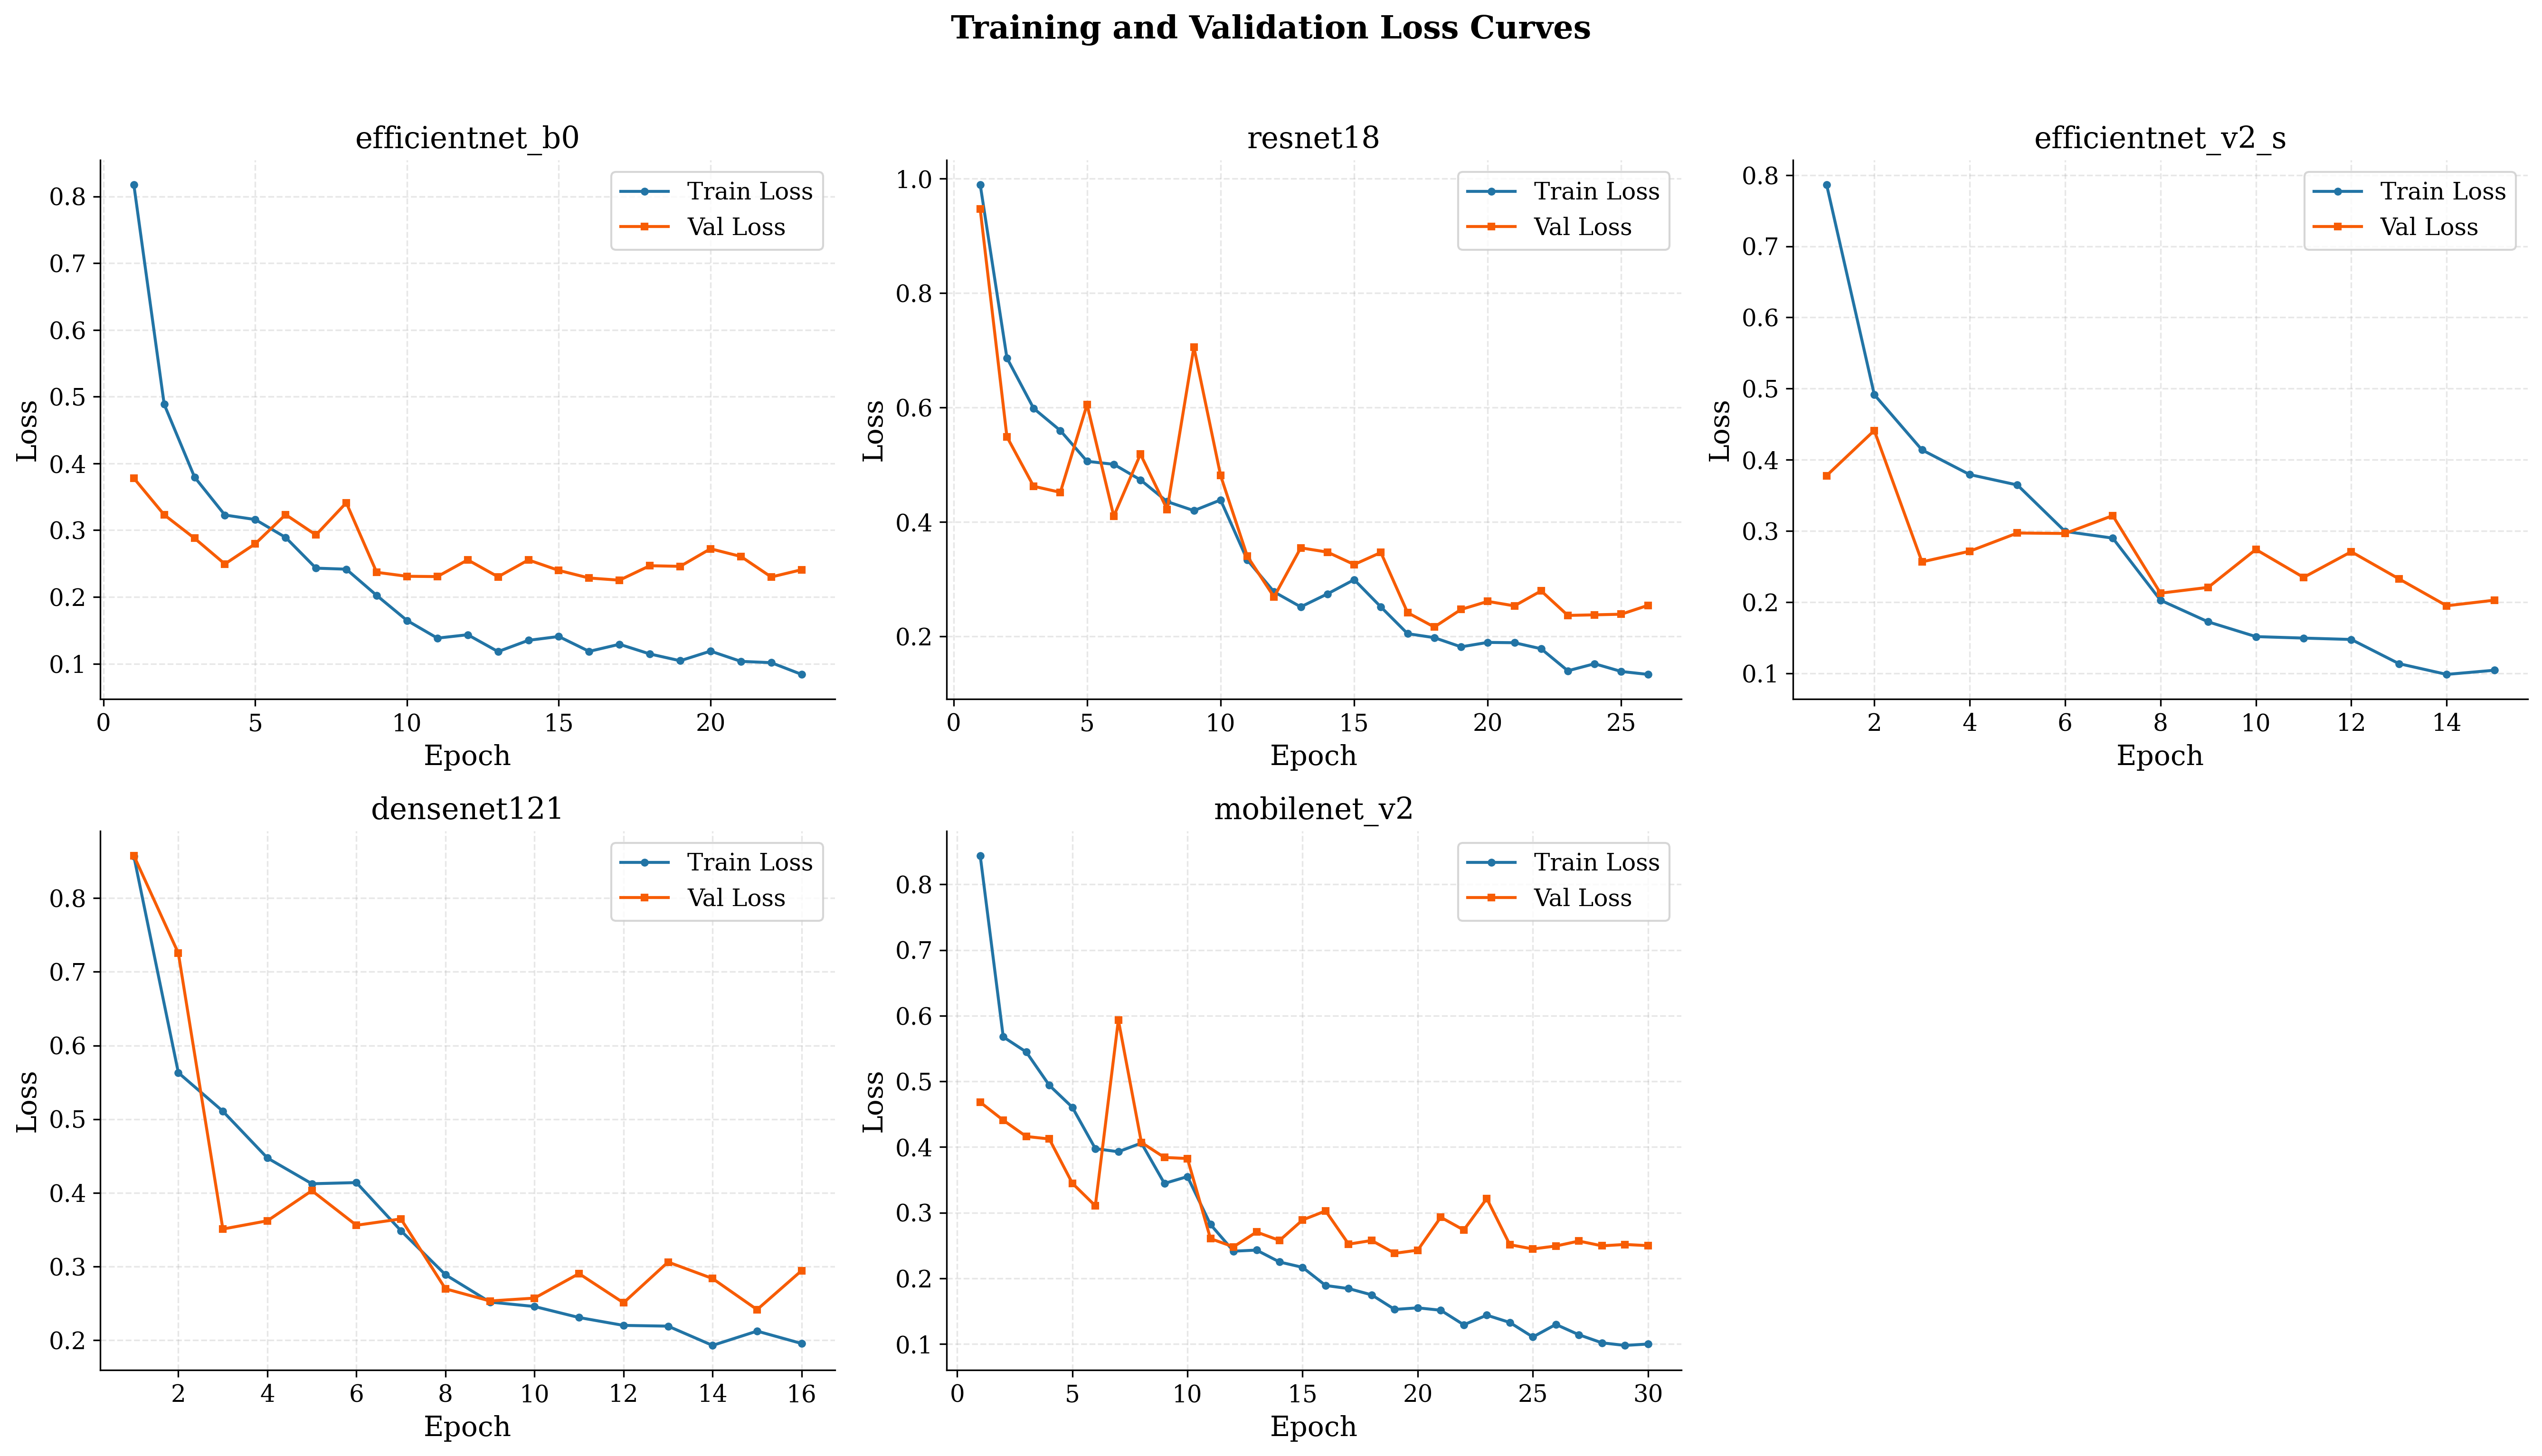

In [ ]:
n_models = len(all_results)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (model_name, results) in enumerate(all_results.items()):
    ax = axes[idx]
    epochs = range(1, len(results['history']['train_loss']) + 1)
    ax.plot(epochs, results['history']['train_loss'], '-o', color='#2274A5', label='Train Loss', markersize=3)
    ax.plot(epochs, results['history']['val_loss'], '-s', color='#F75C03', label='Val Loss', markersize=3)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Loss'); ax.set_title(model_name)
    ax.legend(); ax.grid(True, alpha=0.3, linestyle='--')

for idx in range(n_models, len(axes)): axes[idx].set_visible(False)
fig.suptitle('Training and Validation Loss Curves', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig3_loss_curves.png', dpi=300, bbox_inches='tight')
plt.show()

###Accuracy Curves (per model subplots) — Acc vs Epoch

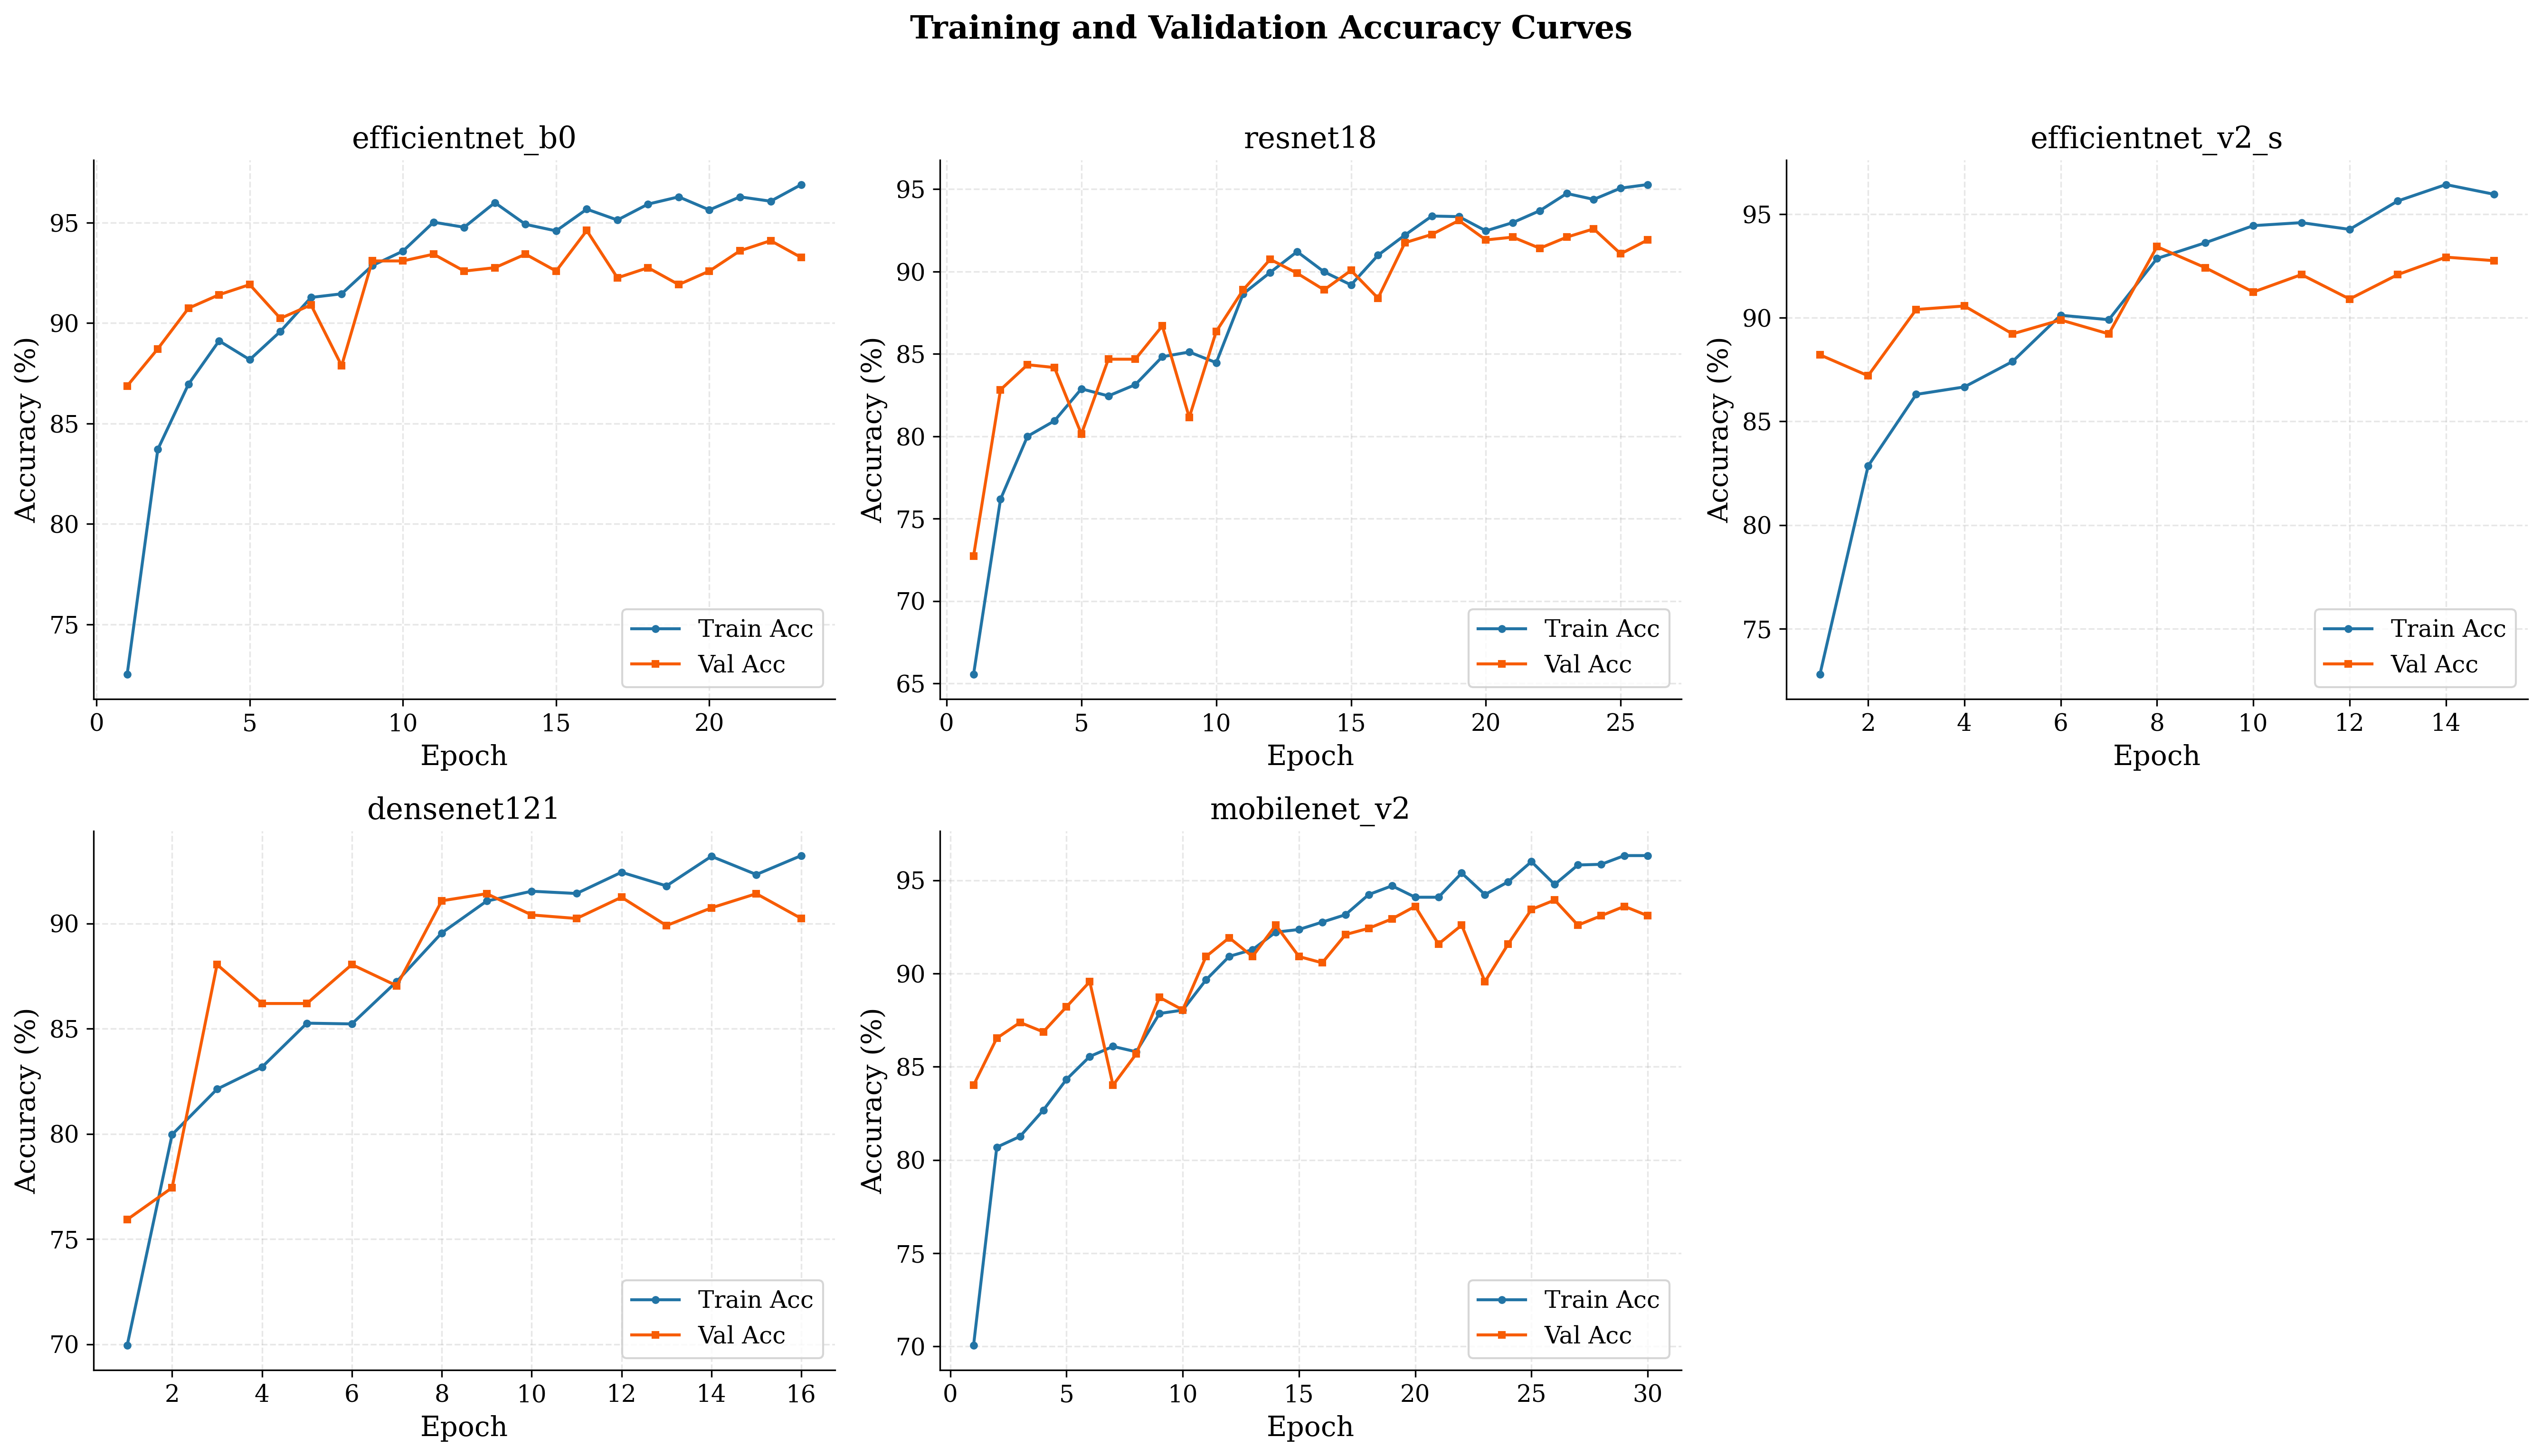

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (model_name, results) in enumerate(all_results.items()):
    ax = axes[idx]
    epochs = range(1, len(results['history']['train_acc']) + 1)
    ax.plot(epochs, results['history']['train_acc'], '-o', color='#2274A5', label='Train Acc', markersize=3)
    ax.plot(epochs, results['history']['val_acc'], '-s', color='#F75C03', label='Val Acc', markersize=3)
    ax.set_xlabel('Epoch'); ax.set_ylabel('Accuracy (%)'); ax.set_title(model_name)
    ax.legend(loc='lower right'); ax.grid(True, alpha=0.3, linestyle='--')

for idx in range(n_models, len(axes)): axes[idx].set_visible(False)
fig.suptitle('Training and Validation Accuracy Curves', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('fig4_accuracy_curves.png', dpi=300, bbox_inches='tight')
plt.show()

###Overlaid Val Loss + Val Accuracy (all models on one plot)

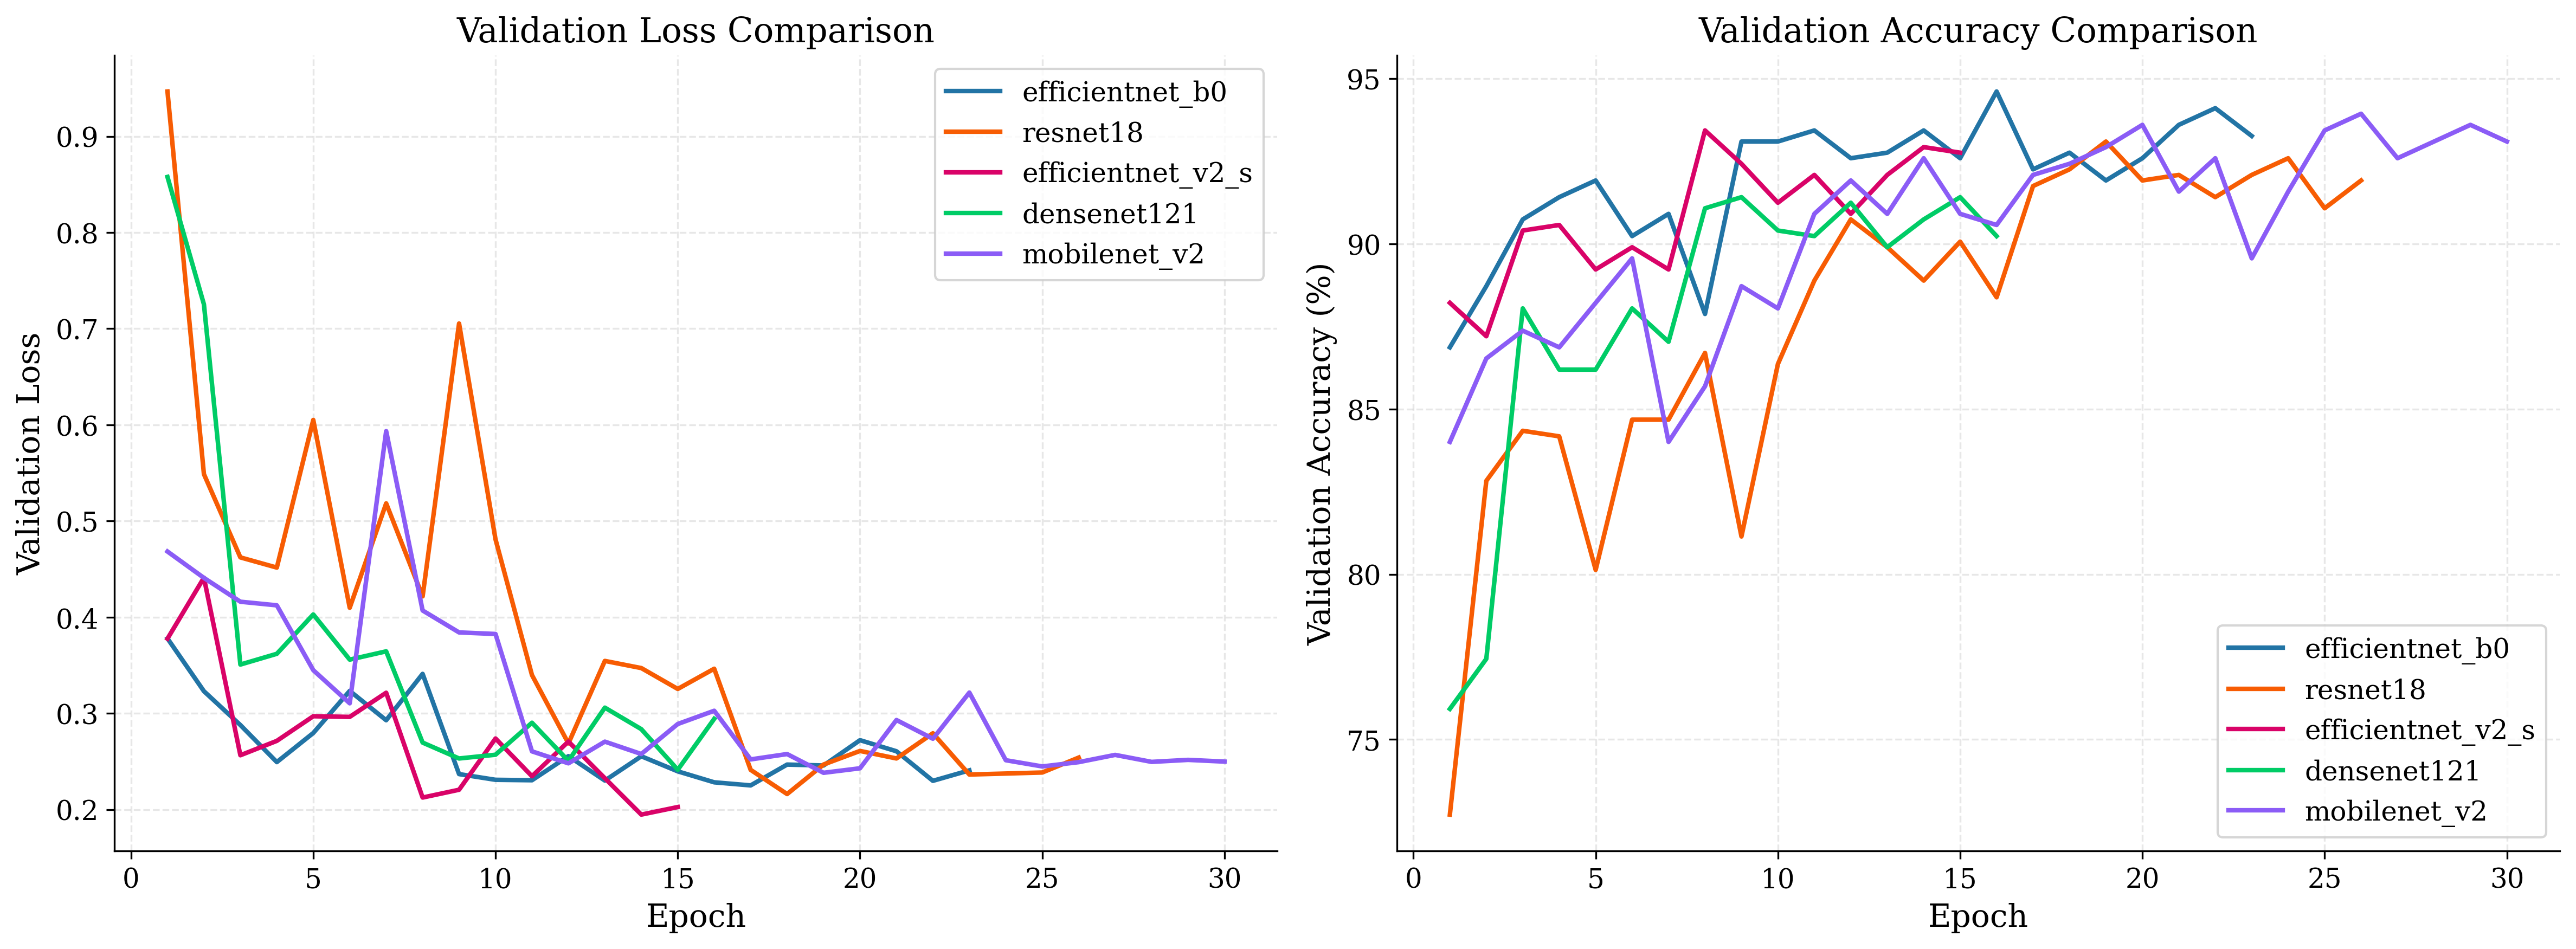

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

for idx, (model_name, results) in enumerate(all_results.items()):
    epochs = range(1, len(results['history']['val_loss']) + 1)
    ax1.plot(epochs, results['history']['val_loss'], '-', color=COLORS[idx], label=model_name, linewidth=2)
    ax2.plot(epochs, results['history']['val_acc'], '-', color=COLORS[idx], label=model_name, linewidth=2)

ax1.set_xlabel('Epoch'); ax1.set_ylabel('Validation Loss'); ax1.set_title('Validation Loss Comparison')
ax1.legend(); ax1.grid(True, alpha=0.3, linestyle='--')
ax2.set_xlabel('Epoch'); ax2.set_ylabel('Validation Accuracy (%)'); ax2.set_title('Validation Accuracy Comparison')
ax2.legend(loc='lower right'); ax2.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('fig5_overlaid_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

###Confusion Matrices (all models)

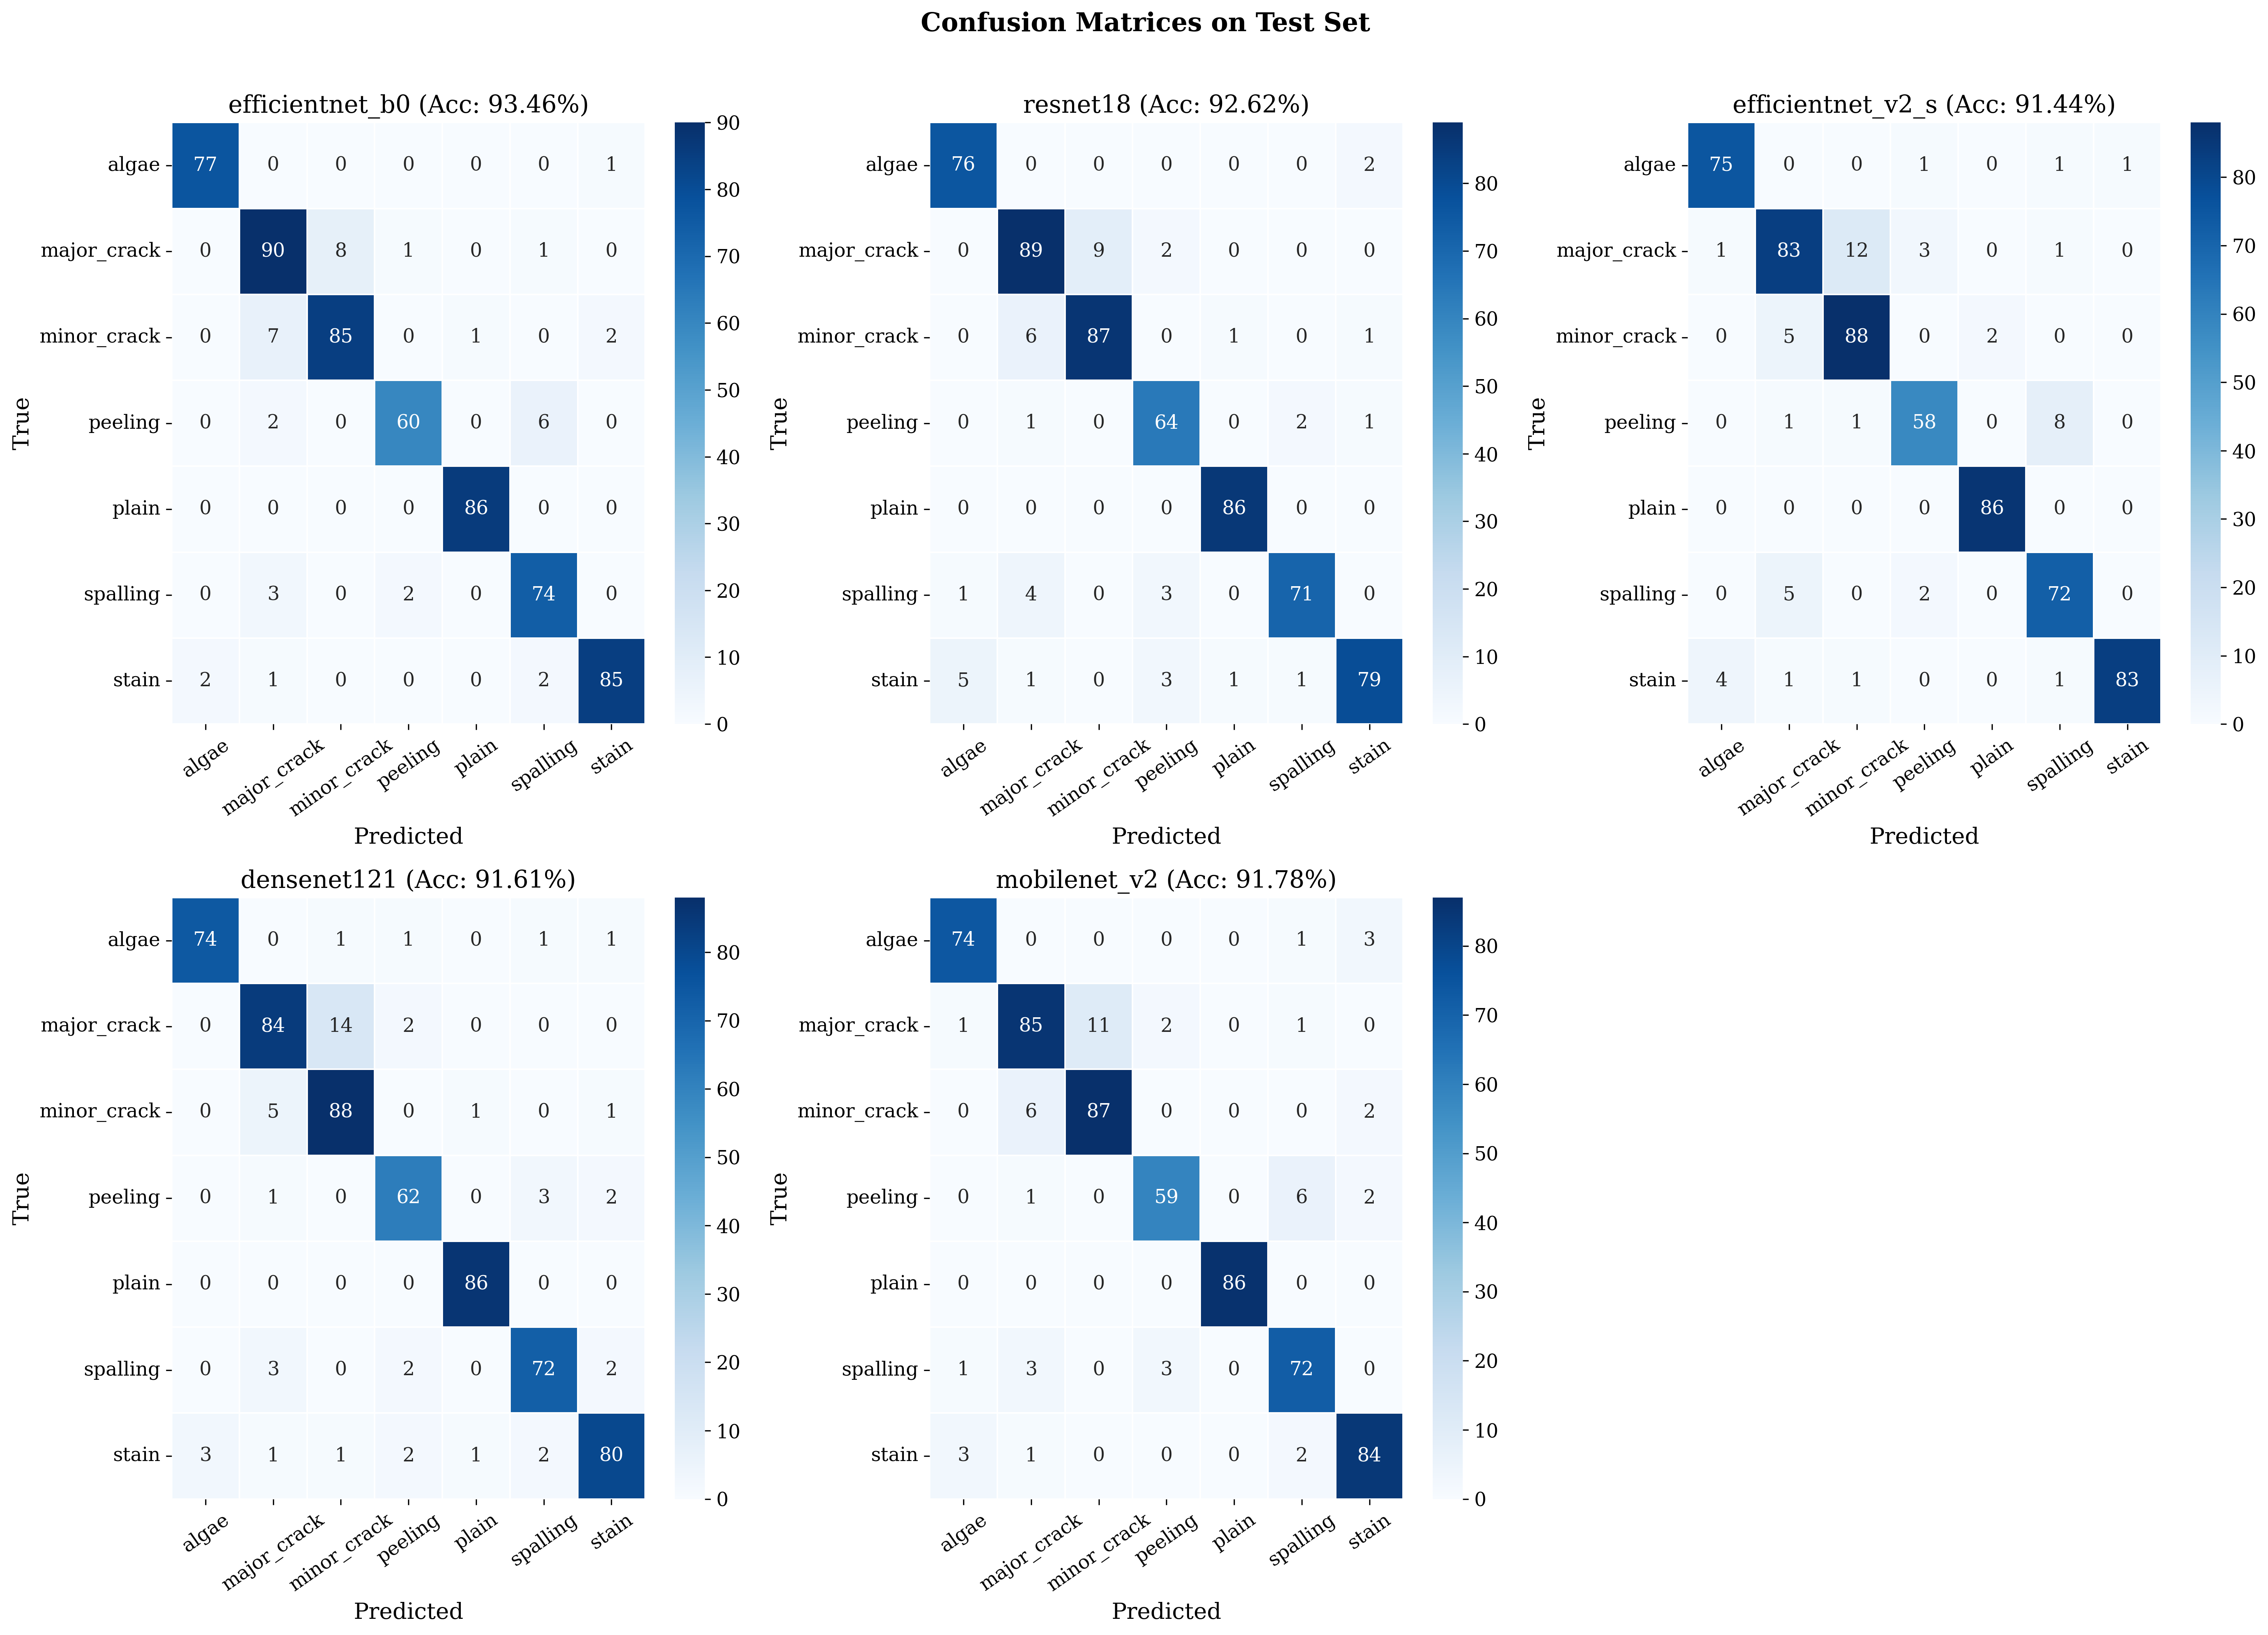

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 14))
axes = axes.flatten()

for idx, (model_name, results) in enumerate(all_results.items()):
    ax = axes[idx]
    cm = confusion_matrix(results['true_labels'], results['predictions'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=class_names, yticklabels=class_names, linewidths=0.5)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{model_name} (Acc: {results["test_acc"]:.2f}%)')
    ax.tick_params(axis='x', rotation=35); ax.tick_params(axis='y', rotation=0)

for idx in range(n_models, len(axes)): axes[idx].set_visible(False)
fig.suptitle('Confusion Matrices on Test Set', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig6_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

### Normalized Confusion Matrices (%)

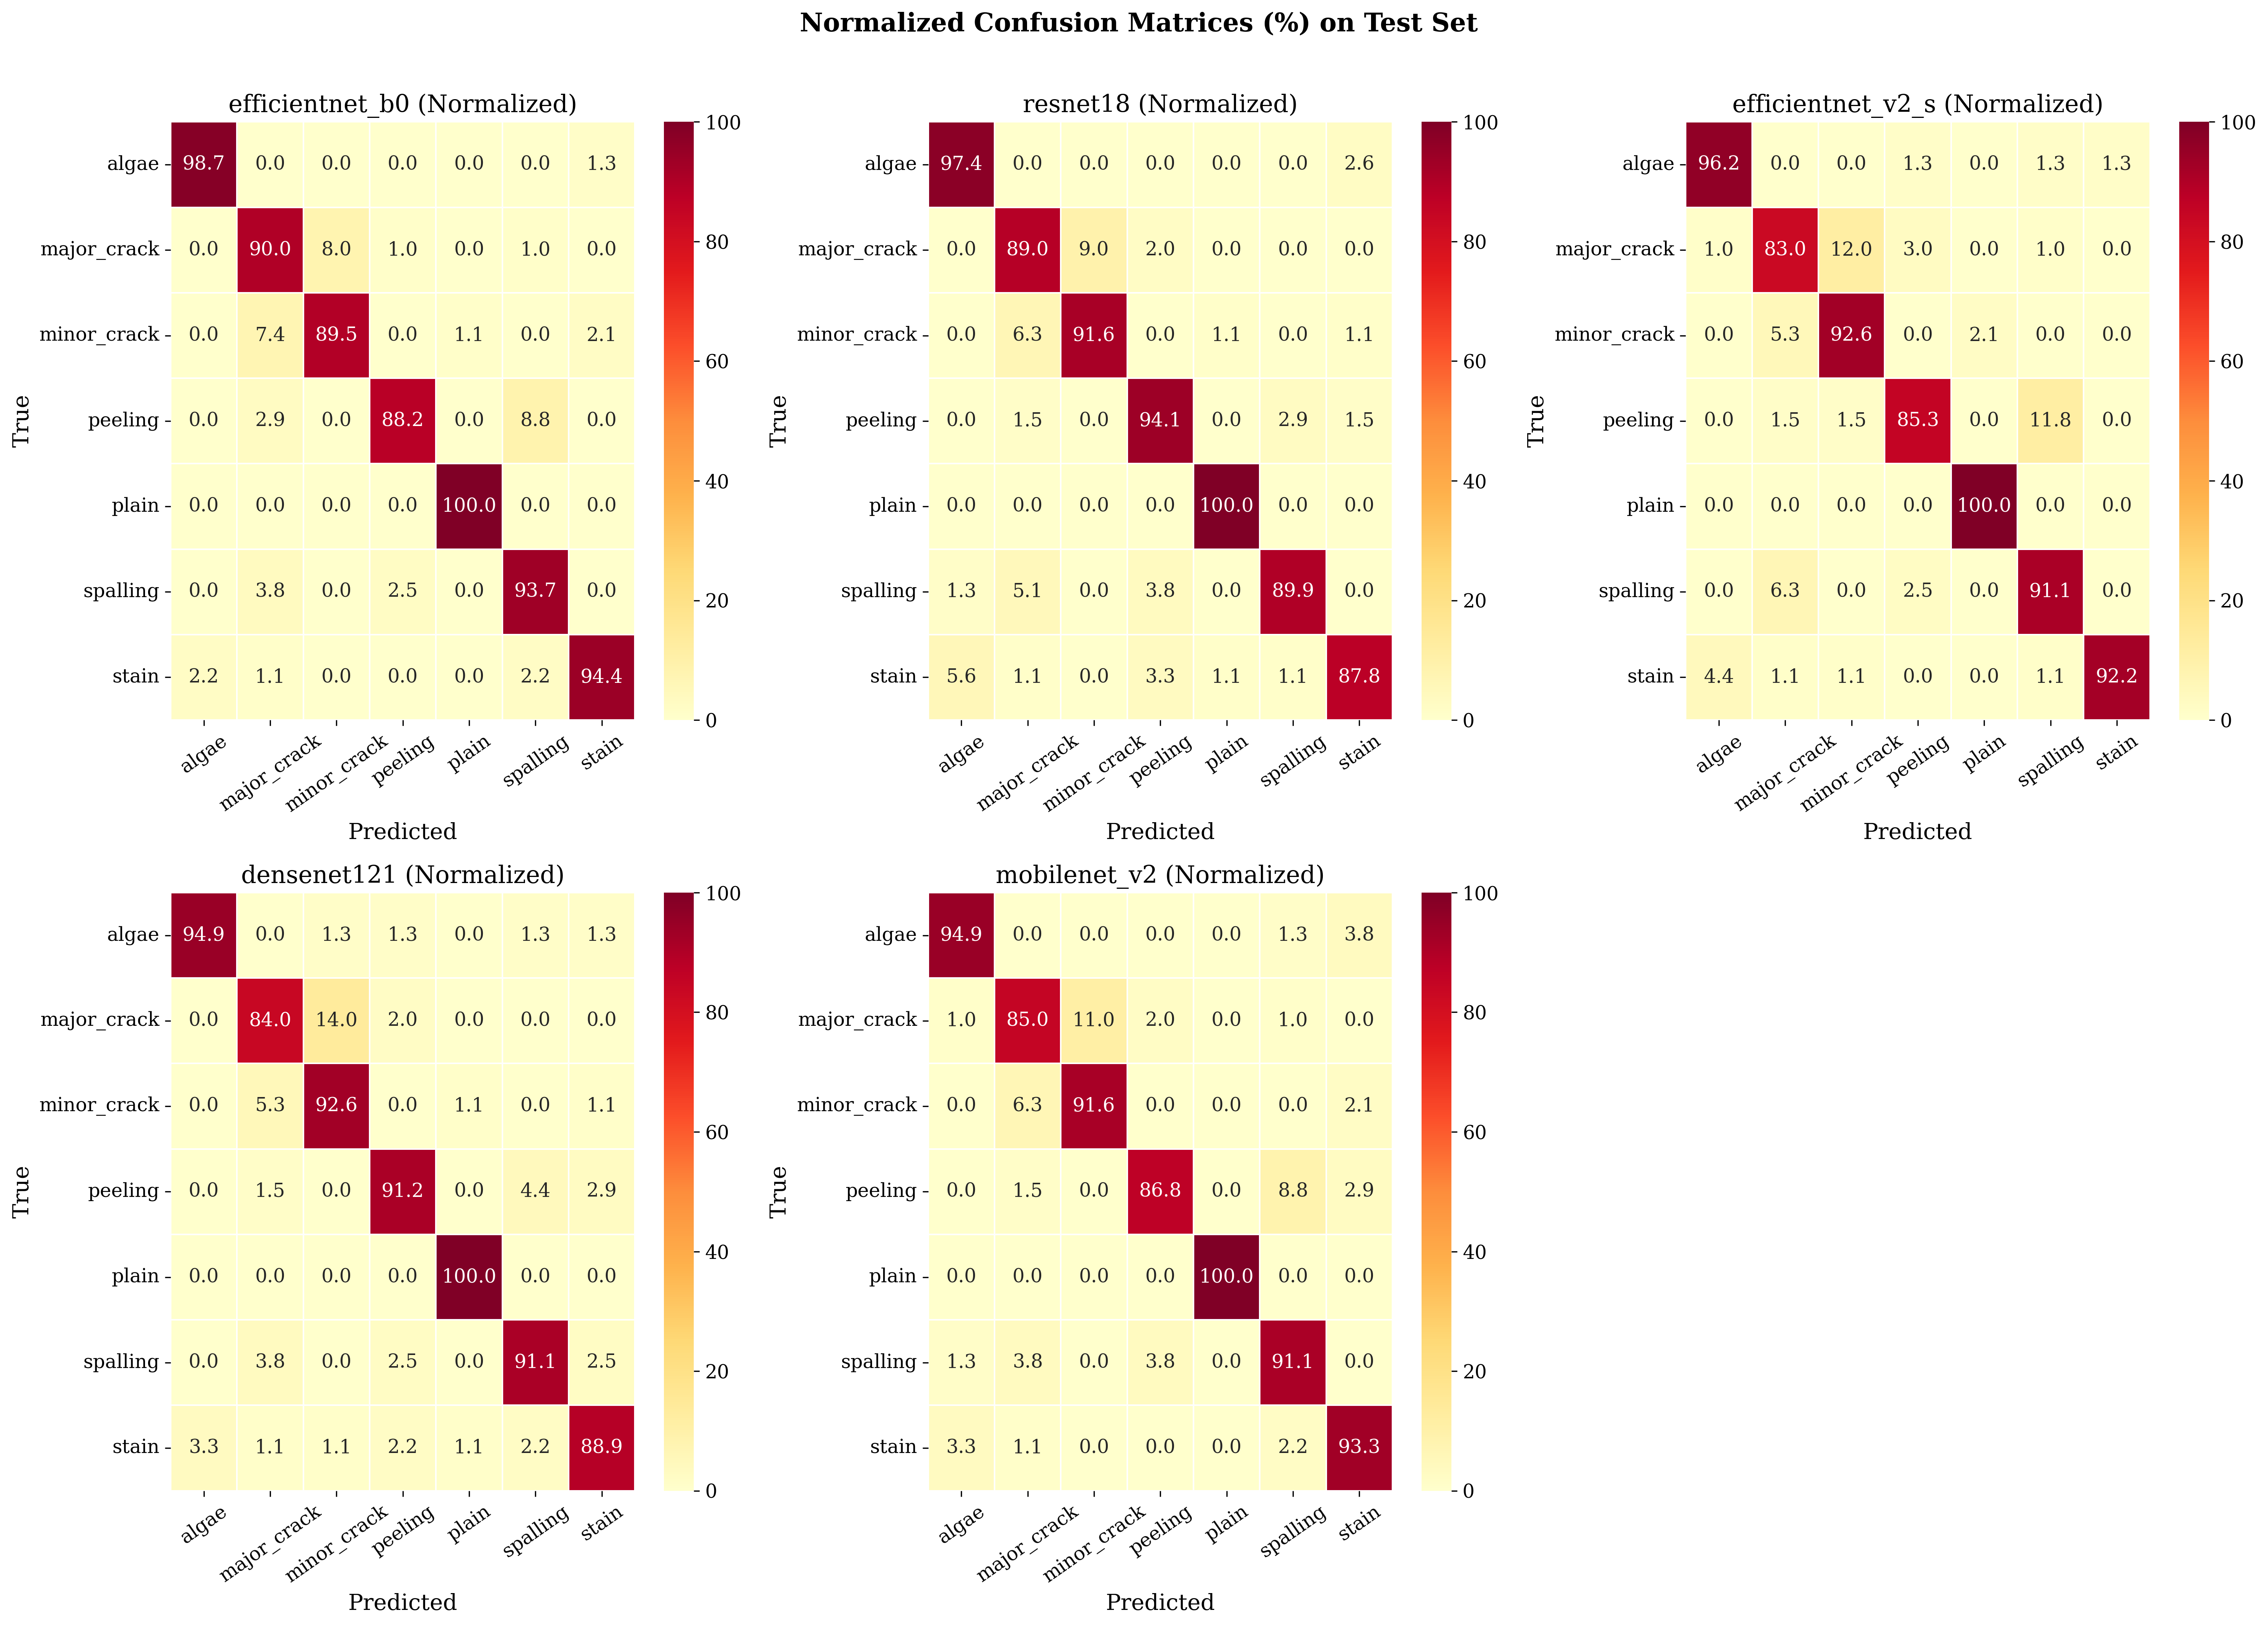

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 14))
axes = axes.flatten()

for idx, (model_name, results) in enumerate(all_results.items()):
    ax = axes[idx]
    cm = confusion_matrix(results['true_labels'], results['predictions'])
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    sns.heatmap(cm_norm, annot=True, fmt='.1f', cmap='YlOrRd', ax=ax,
                xticklabels=class_names, yticklabels=class_names, vmin=0, vmax=100, linewidths=0.5)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
    ax.set_title(f'{model_name} (Normalized)')
    ax.tick_params(axis='x', rotation=35); ax.tick_params(axis='y', rotation=0)

for idx in range(n_models, len(axes)): axes[idx].set_visible(False)
fig.suptitle('Normalized Confusion Matrices (%) on Test Set', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig7_normalized_confusion_matrices.png', dpi=300, bbox_inches='tight')
plt.show()

###Per-Class Precision, Recall, F1 (grouped bars per model)

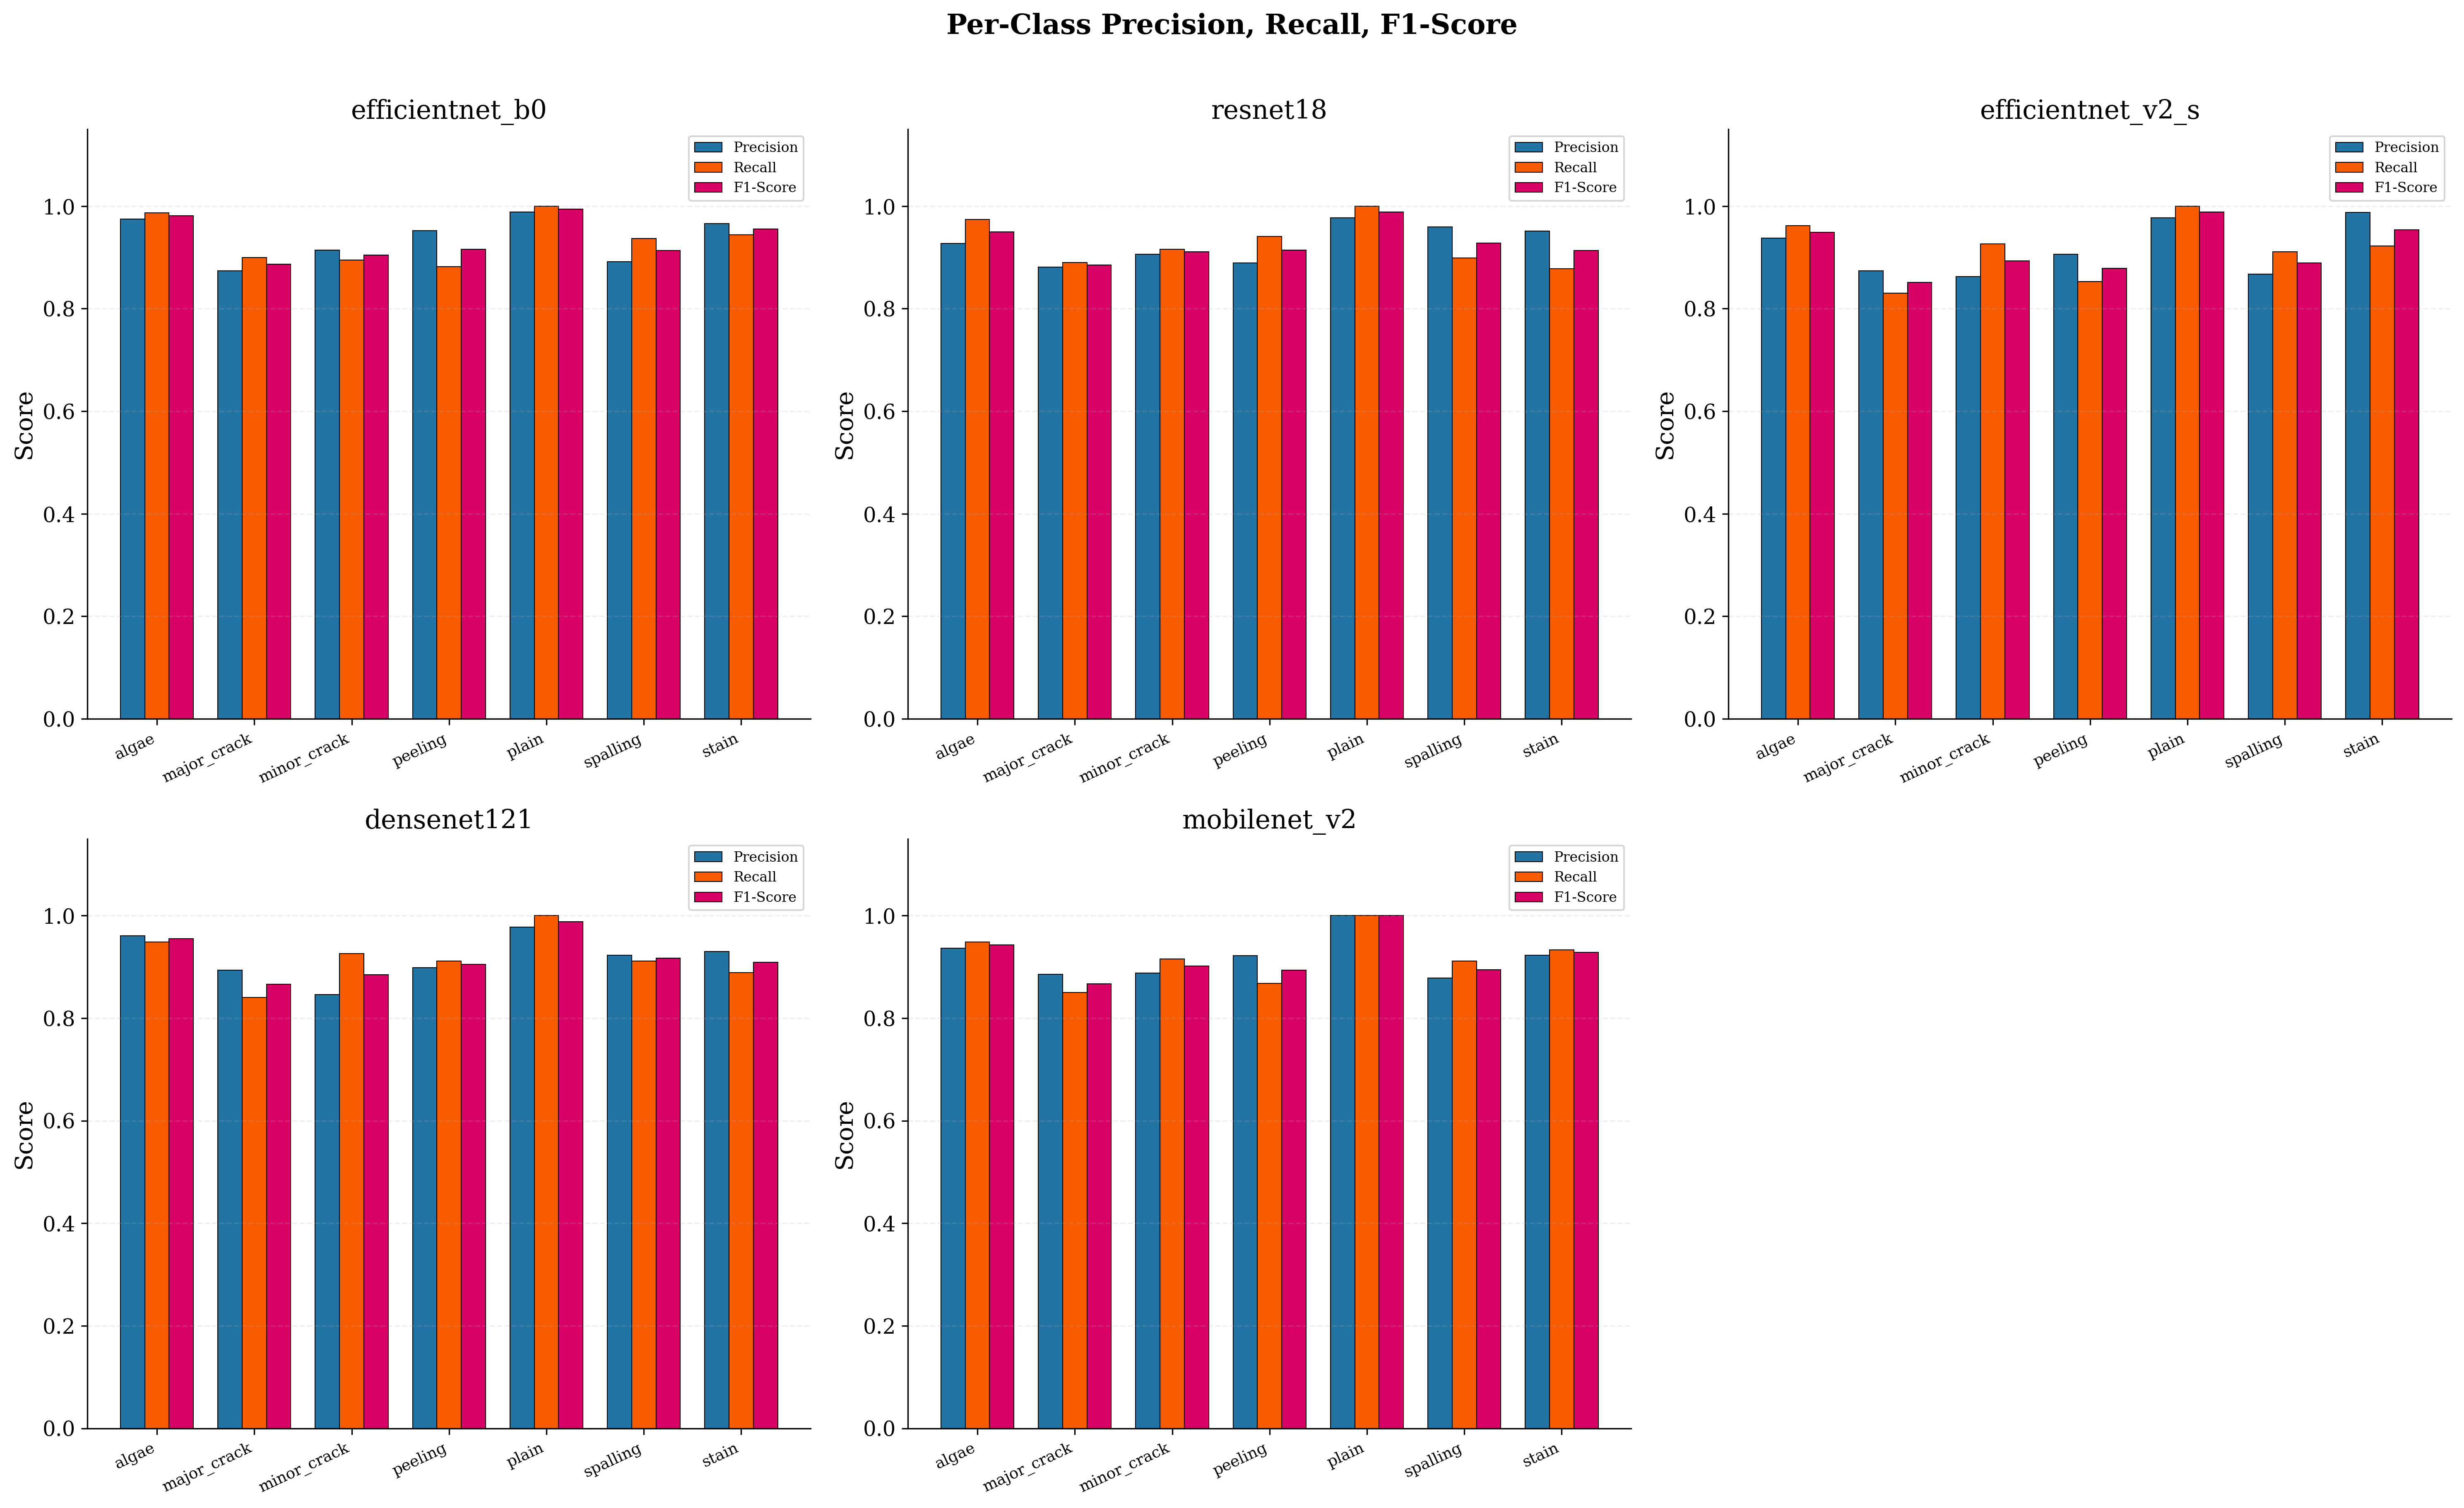

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
axes = axes.flatten()

for idx, (model_name, results) in enumerate(all_results.items()):
    ax = axes[idx]
    prec, rec, f1, _ = precision_recall_fscore_support(
        results['true_labels'], results['predictions'], average=None, zero_division=0)
    x = np.arange(num_classes); width = 0.25
    ax.bar(x - width, prec, width, label='Precision', color='#2274A5', edgecolor='black', linewidth=0.5)
    ax.bar(x, rec, width, label='Recall', color='#F75C03', edgecolor='black', linewidth=0.5)
    ax.bar(x + width, f1, width, label='F1-Score', color='#D90368', edgecolor='black', linewidth=0.5)
    ax.set_xticks(x); ax.set_xticklabels(class_names, rotation=25, ha='right', fontsize=9)
    ax.set_ylim(0, 1.15); ax.set_ylabel('Score'); ax.set_title(model_name)
    ax.legend(fontsize=8); ax.grid(True, alpha=0.2, linestyle='--', axis='y')

for idx in range(n_models, len(axes)): axes[idx].set_visible(False)
fig.suptitle('Per-Class Precision, Recall, F1-Score', fontsize=16, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('fig8_per_class_metrics.png', dpi=300, bbox_inches='tight')
plt.show()

###Model Comparison Bar Chart (Val vs Test Accuracy)

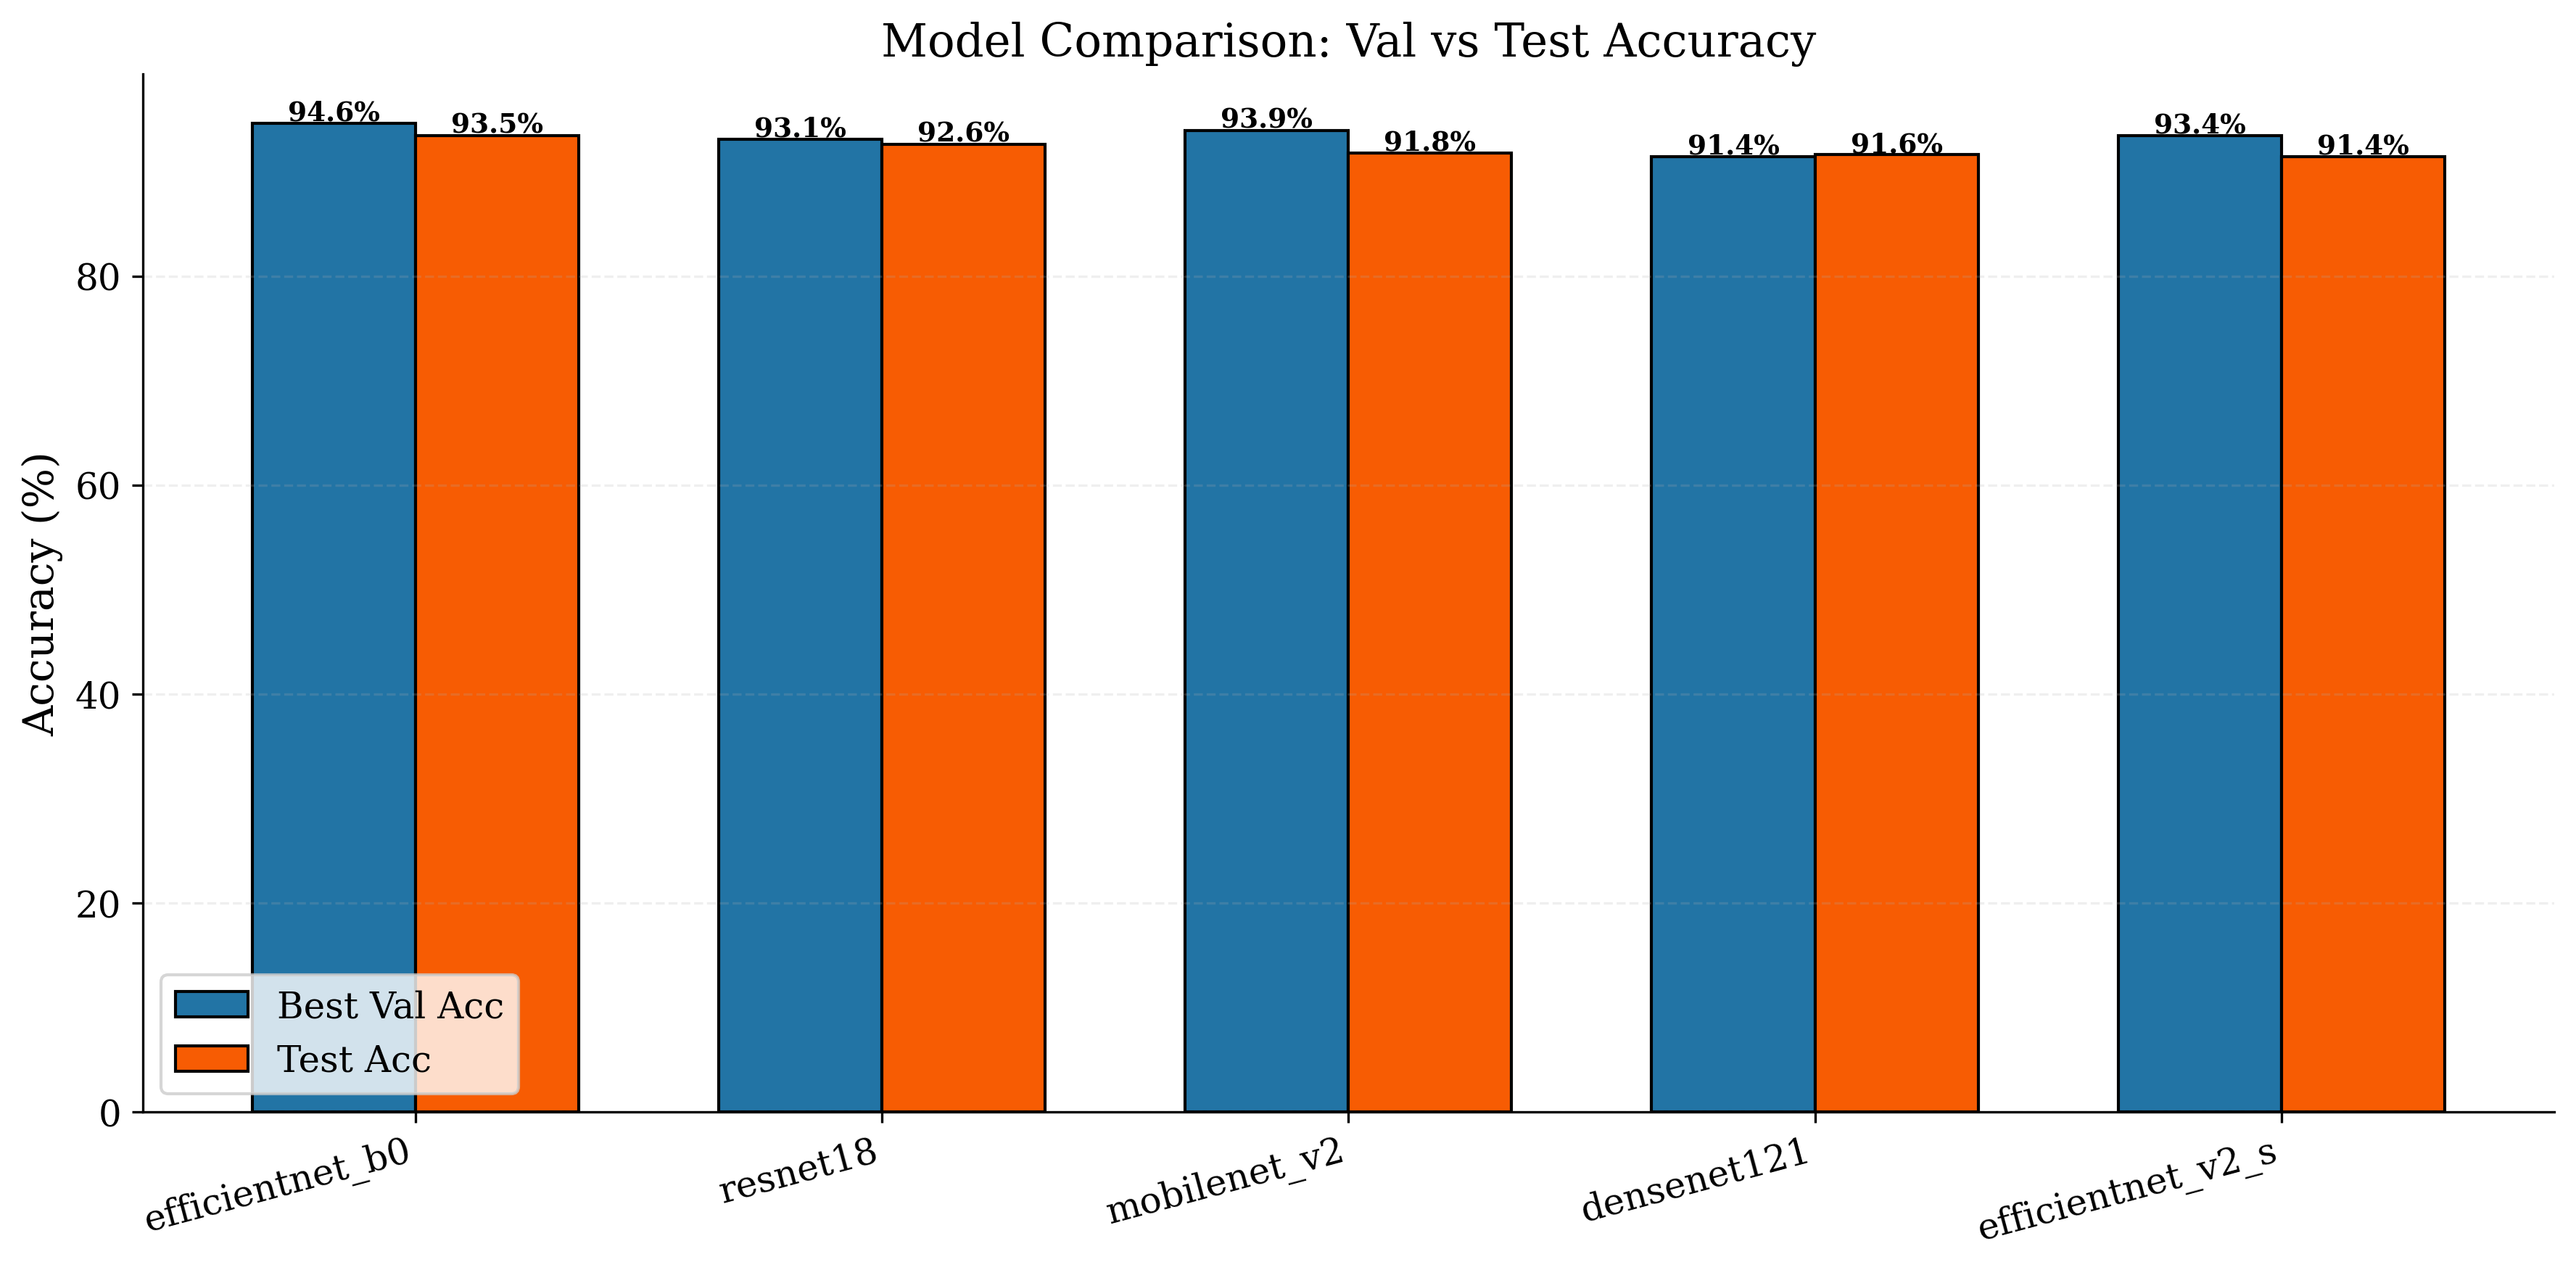

In [ ]:
sorted_res = dict(sorted(all_results.items(), key=lambda x: x[1]['test_acc'], reverse=True))
names = list(sorted_res.keys())
test_accs = [sorted_res[m]['test_acc'] for m in names]
val_accs = [sorted_res[m]['best_val_acc'] for m in names]

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(names)); width = 0.35
b1 = ax.bar(x - width/2, val_accs, width, label='Best Val Acc', color='#2274A5', edgecolor='black')
b2 = ax.bar(x + width/2, test_accs, width, label='Test Acc', color='#F75C03', edgecolor='black')
for bar in b1 + b2:
    ax.text(bar.get_x()+bar.get_width()/2., bar.get_height()+0.3,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15, ha='right')
ax.set_ylabel('Accuracy (%)'); ax.set_title('Model Comparison: Val vs Test Accuracy')
ax.legend(); ax.grid(True, alpha=0.2, linestyle='--', axis='y')
plt.tight_layout()
plt.savefig('fig9_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

###Accuracy vs Parameters Scatter (Efficiency)

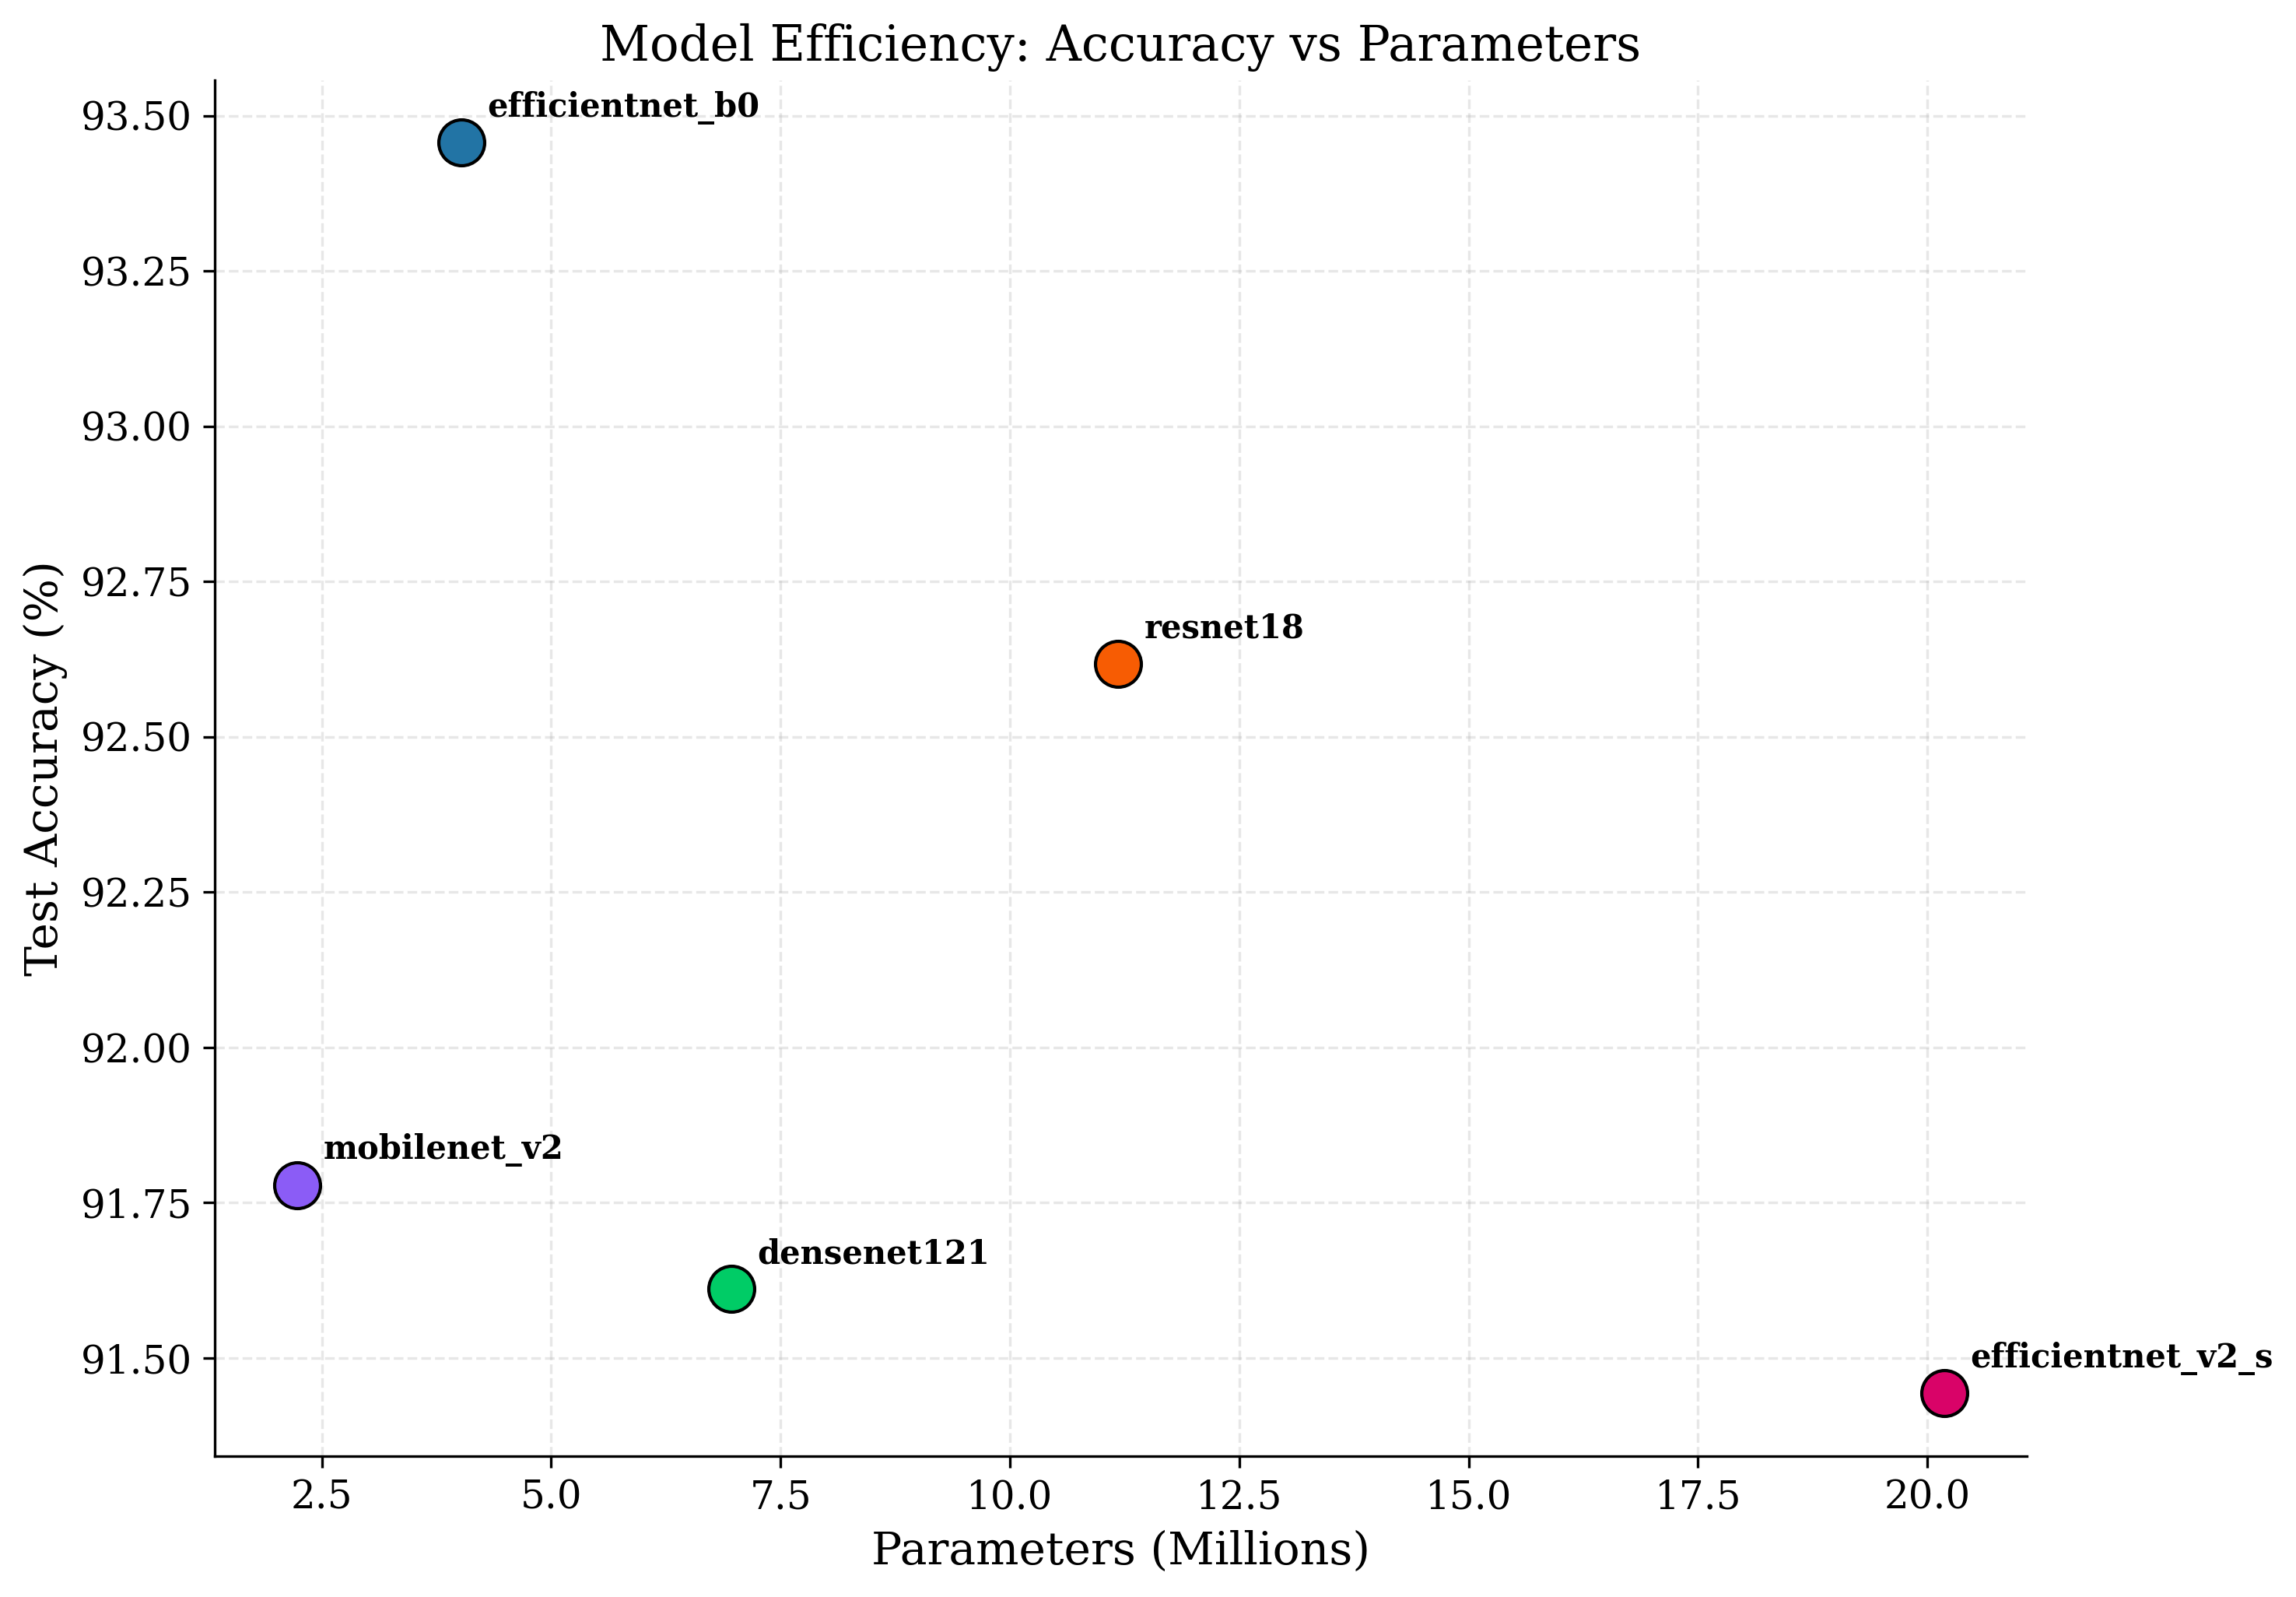

In [ ]:
fig, ax = plt.subplots(figsize=(10, 7))
for idx, (model_name, results) in enumerate(all_results.items()):
    params_m = results['total_params'] / 1e6
    ax.scatter(params_m, results['test_acc'], s=200, color=COLORS[idx], edgecolors='black', linewidth=1, zorder=5)
    ax.annotate(model_name, (params_m, results['test_acc']), textcoords="offset points",
                xytext=(8, 8), fontsize=10, fontweight='bold')
ax.set_xlabel('Parameters (Millions)'); ax.set_ylabel('Test Accuracy (%)')
ax.set_title('Model Efficiency: Accuracy vs Parameters'); ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('fig10_accuracy_vs_params.png', dpi=300, bbox_inches='tight')
plt.show()

###ROC Curves (best model, per class)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
Computing ROC: 100%|██████████| 19/19 [00:02<00:00,  7.31it/s]


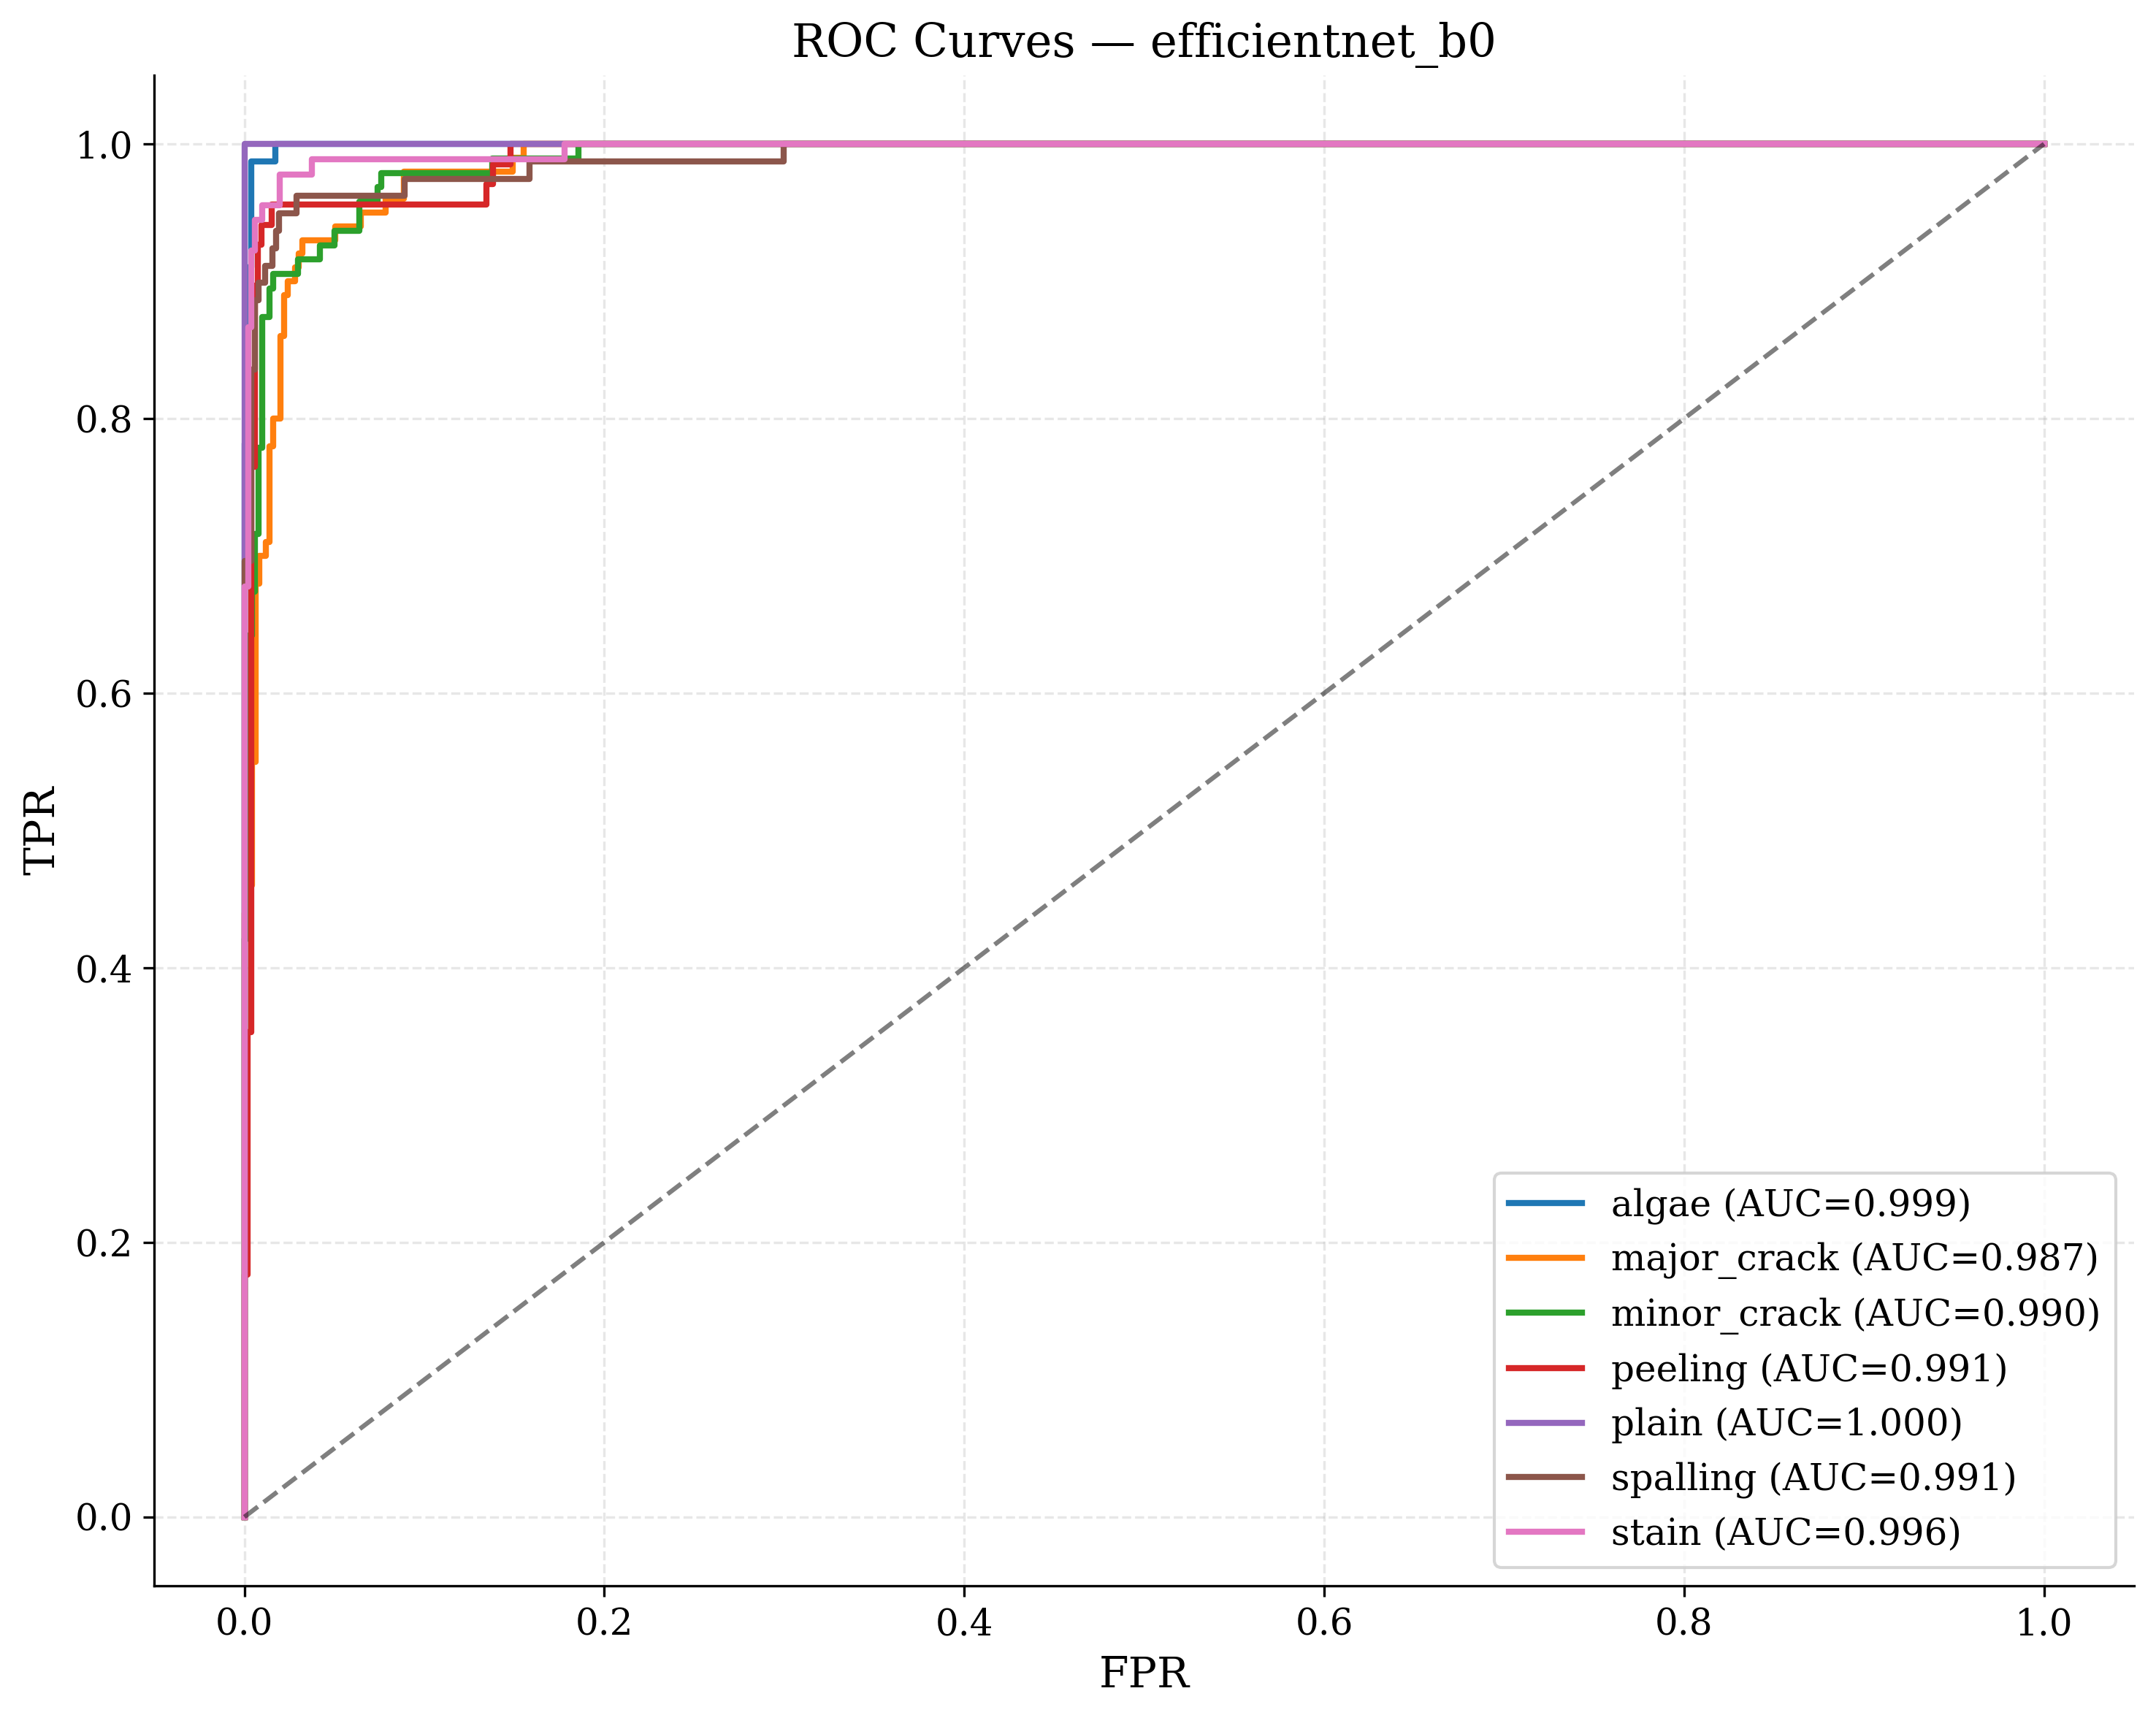

In [ ]:
best_model = get_model(best_model_name, num_classes, dropout=0.3)
best_model.load_state_dict(torch.load(f'best_{best_model_name}.pth'))
best_model = best_model.to(device)
best_model.eval()

all_probs, all_labels_roc = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Computing ROC'):
        images = images.to(device)
        probs = F.softmax(best_model(images), dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels_roc.extend(labels.numpy())

all_probs = np.concatenate(all_probs); all_labels_roc = np.array(all_labels_roc)
labels_onehot = label_binarize(all_labels_roc, classes=list(range(num_classes)))

fig, ax = plt.subplots(figsize=(10, 8))
for i in range(num_classes):
    fpr, tpr, _ = roc_curve(labels_onehot[:, i], all_probs[:, i])
    ax.plot(fpr, tpr, linewidth=2, label=f'{class_names[i]} (AUC={auc(fpr,tpr):.3f})')
ax.plot([0,1],[0,1],'k--', alpha=0.5); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title(f'ROC Curves — {best_model_name}'); ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('fig11_roc_best_model.png', dpi=300, bbox_inches='tight')
plt.show()

###Precision-Recall Curves (best model)

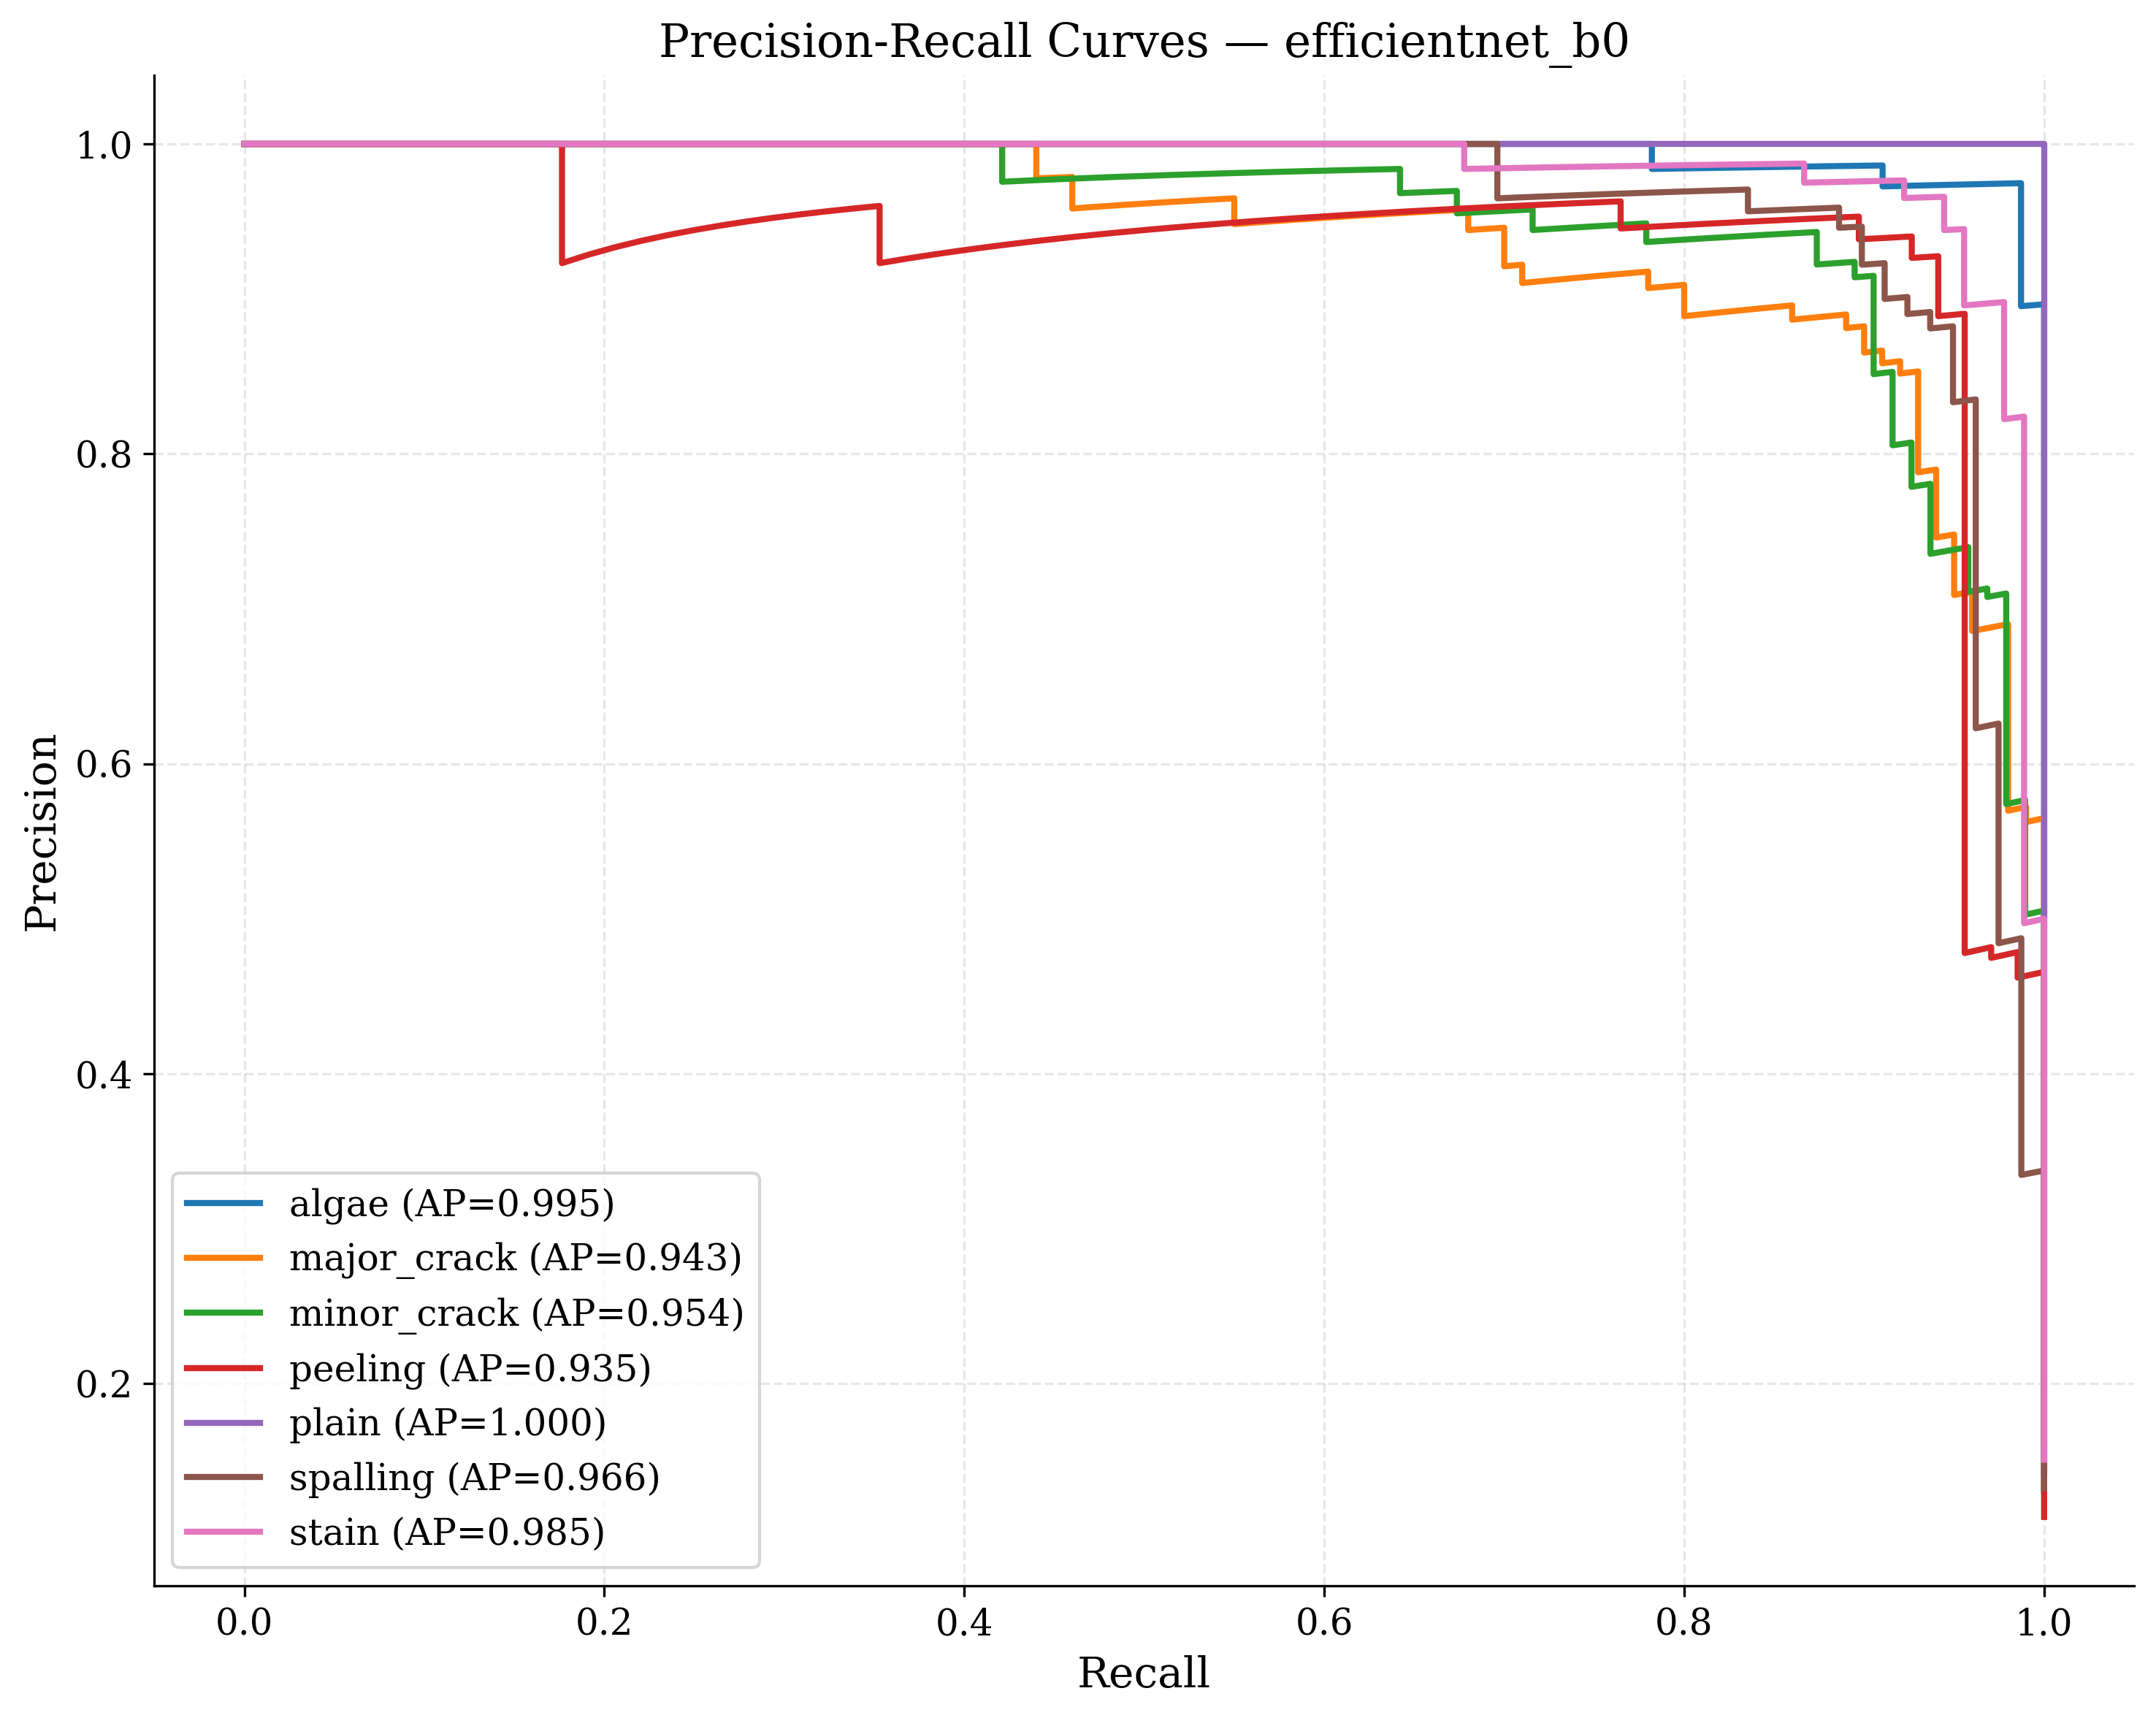

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
for i in range(num_classes):
    prec_vals, rec_vals, _ = precision_recall_curve(labels_onehot[:, i], all_probs[:, i])
    ap = average_precision_score(labels_onehot[:, i], all_probs[:, i])
    ax.plot(rec_vals, prec_vals, linewidth=2, label=f'{class_names[i]} (AP={ap:.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title(f'Precision-Recall Curves — {best_model_name}'); ax.legend(loc='lower left')
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('fig12_precision_recall_curves.png', dpi=300, bbox_inches='tight')
plt.show()

###Macro ROC Comparison (all models)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=EfficientNet_B0_Weights.IMAGENET1K_V1`. You can also use `weights=EfficientNet_B0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weight

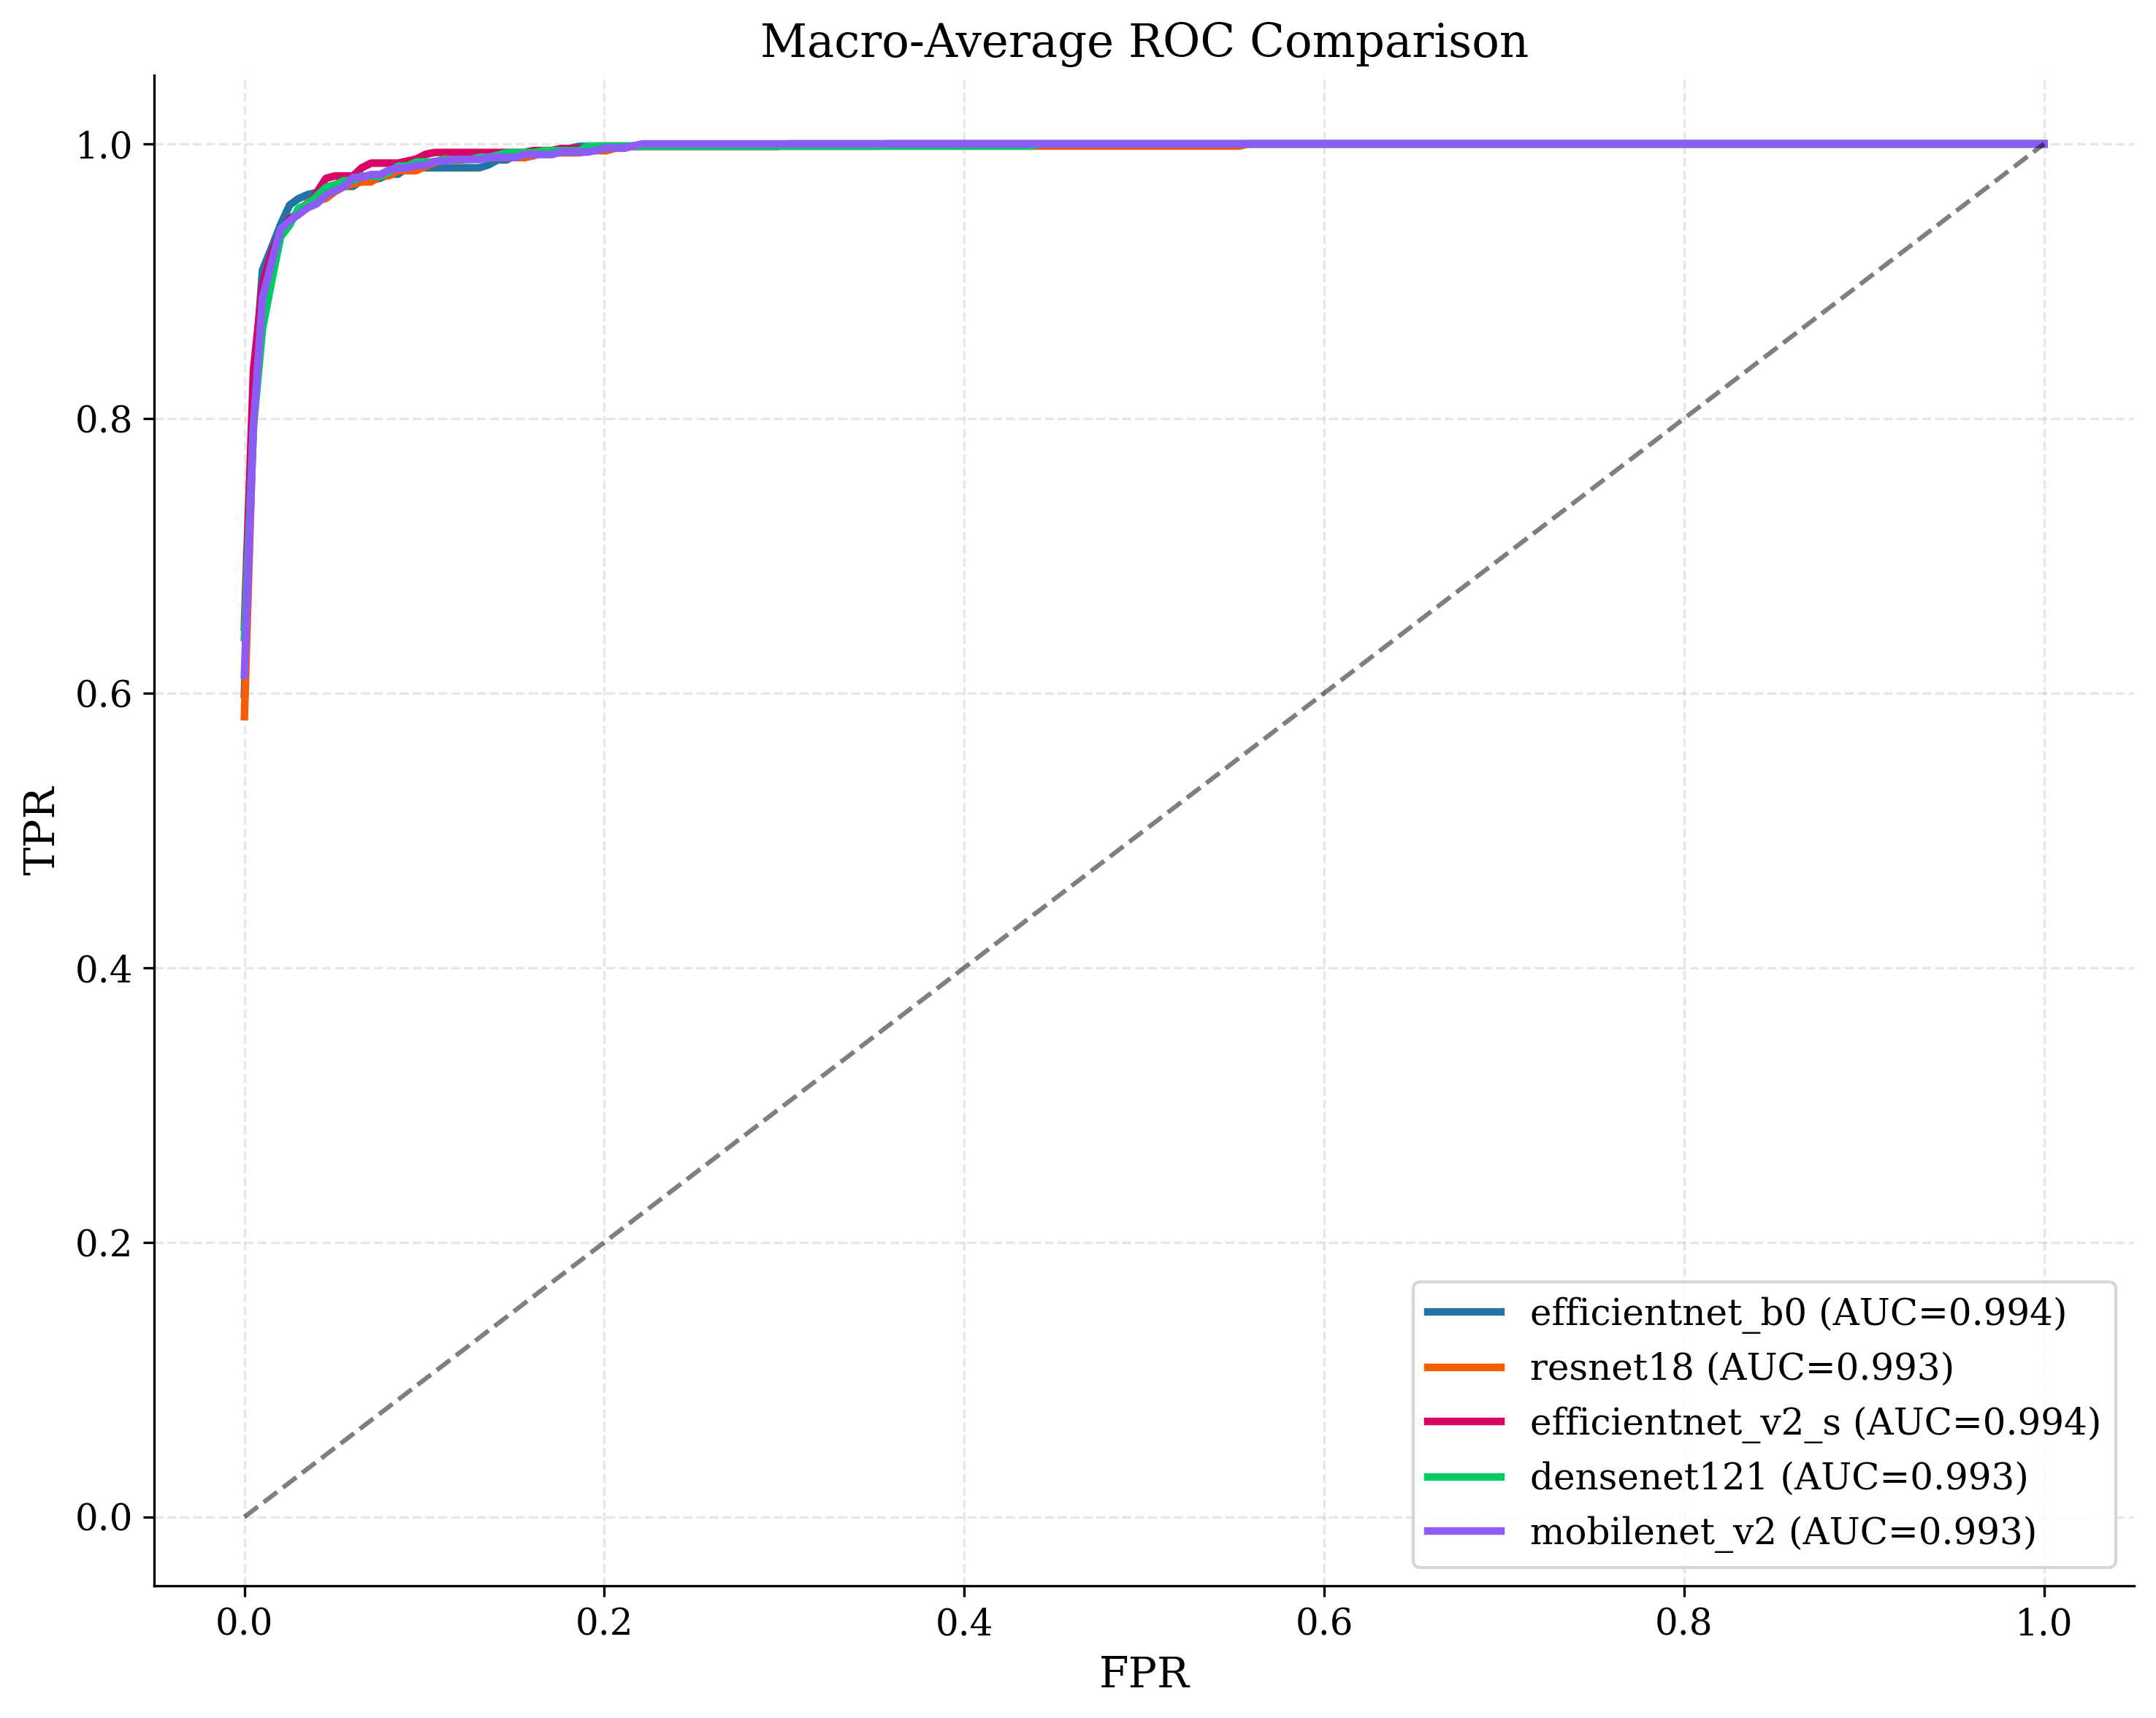

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
for idx, (model_name, results) in enumerate(all_results.items()):
    model_temp = get_model(model_name, num_classes, dropout=0.3)
    model_temp.load_state_dict(torch.load(f'best_{model_name}.pth'))
    model_temp = model_temp.to(device); model_temp.eval()

    probs_t, labels_t = [], []
    with torch.no_grad():
        for images, labels in test_loader:
            probs_t.append(F.softmax(model_temp(images.to(device)), dim=1).cpu().numpy())
            labels_t.extend(labels.numpy())
    probs_t = np.concatenate(probs_t); labels_oh = label_binarize(labels_t, classes=list(range(num_classes)))

    all_fpr = np.linspace(0, 1, 200); mean_tpr = np.zeros_like(all_fpr)
    for i in range(num_classes):
        fpr, tpr, _ = roc_curve(labels_oh[:, i], probs_t[:, i])
        mean_tpr += np.interp(all_fpr, fpr, tpr)
    mean_tpr /= num_classes
    ax.plot(all_fpr, mean_tpr, linewidth=2.5, color=COLORS[idx],
            label=f'{model_name} (AUC={auc(all_fpr, mean_tpr):.3f})')
    del model_temp

ax.plot([0,1],[0,1],'k--', alpha=0.5); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
ax.set_title('Macro-Average ROC Comparison'); ax.legend(loc='lower right')
ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('fig13_roc_all_models.png', dpi=300, bbox_inches='tight')
plt.show()

###F1-Score Heatmap (models × classes)

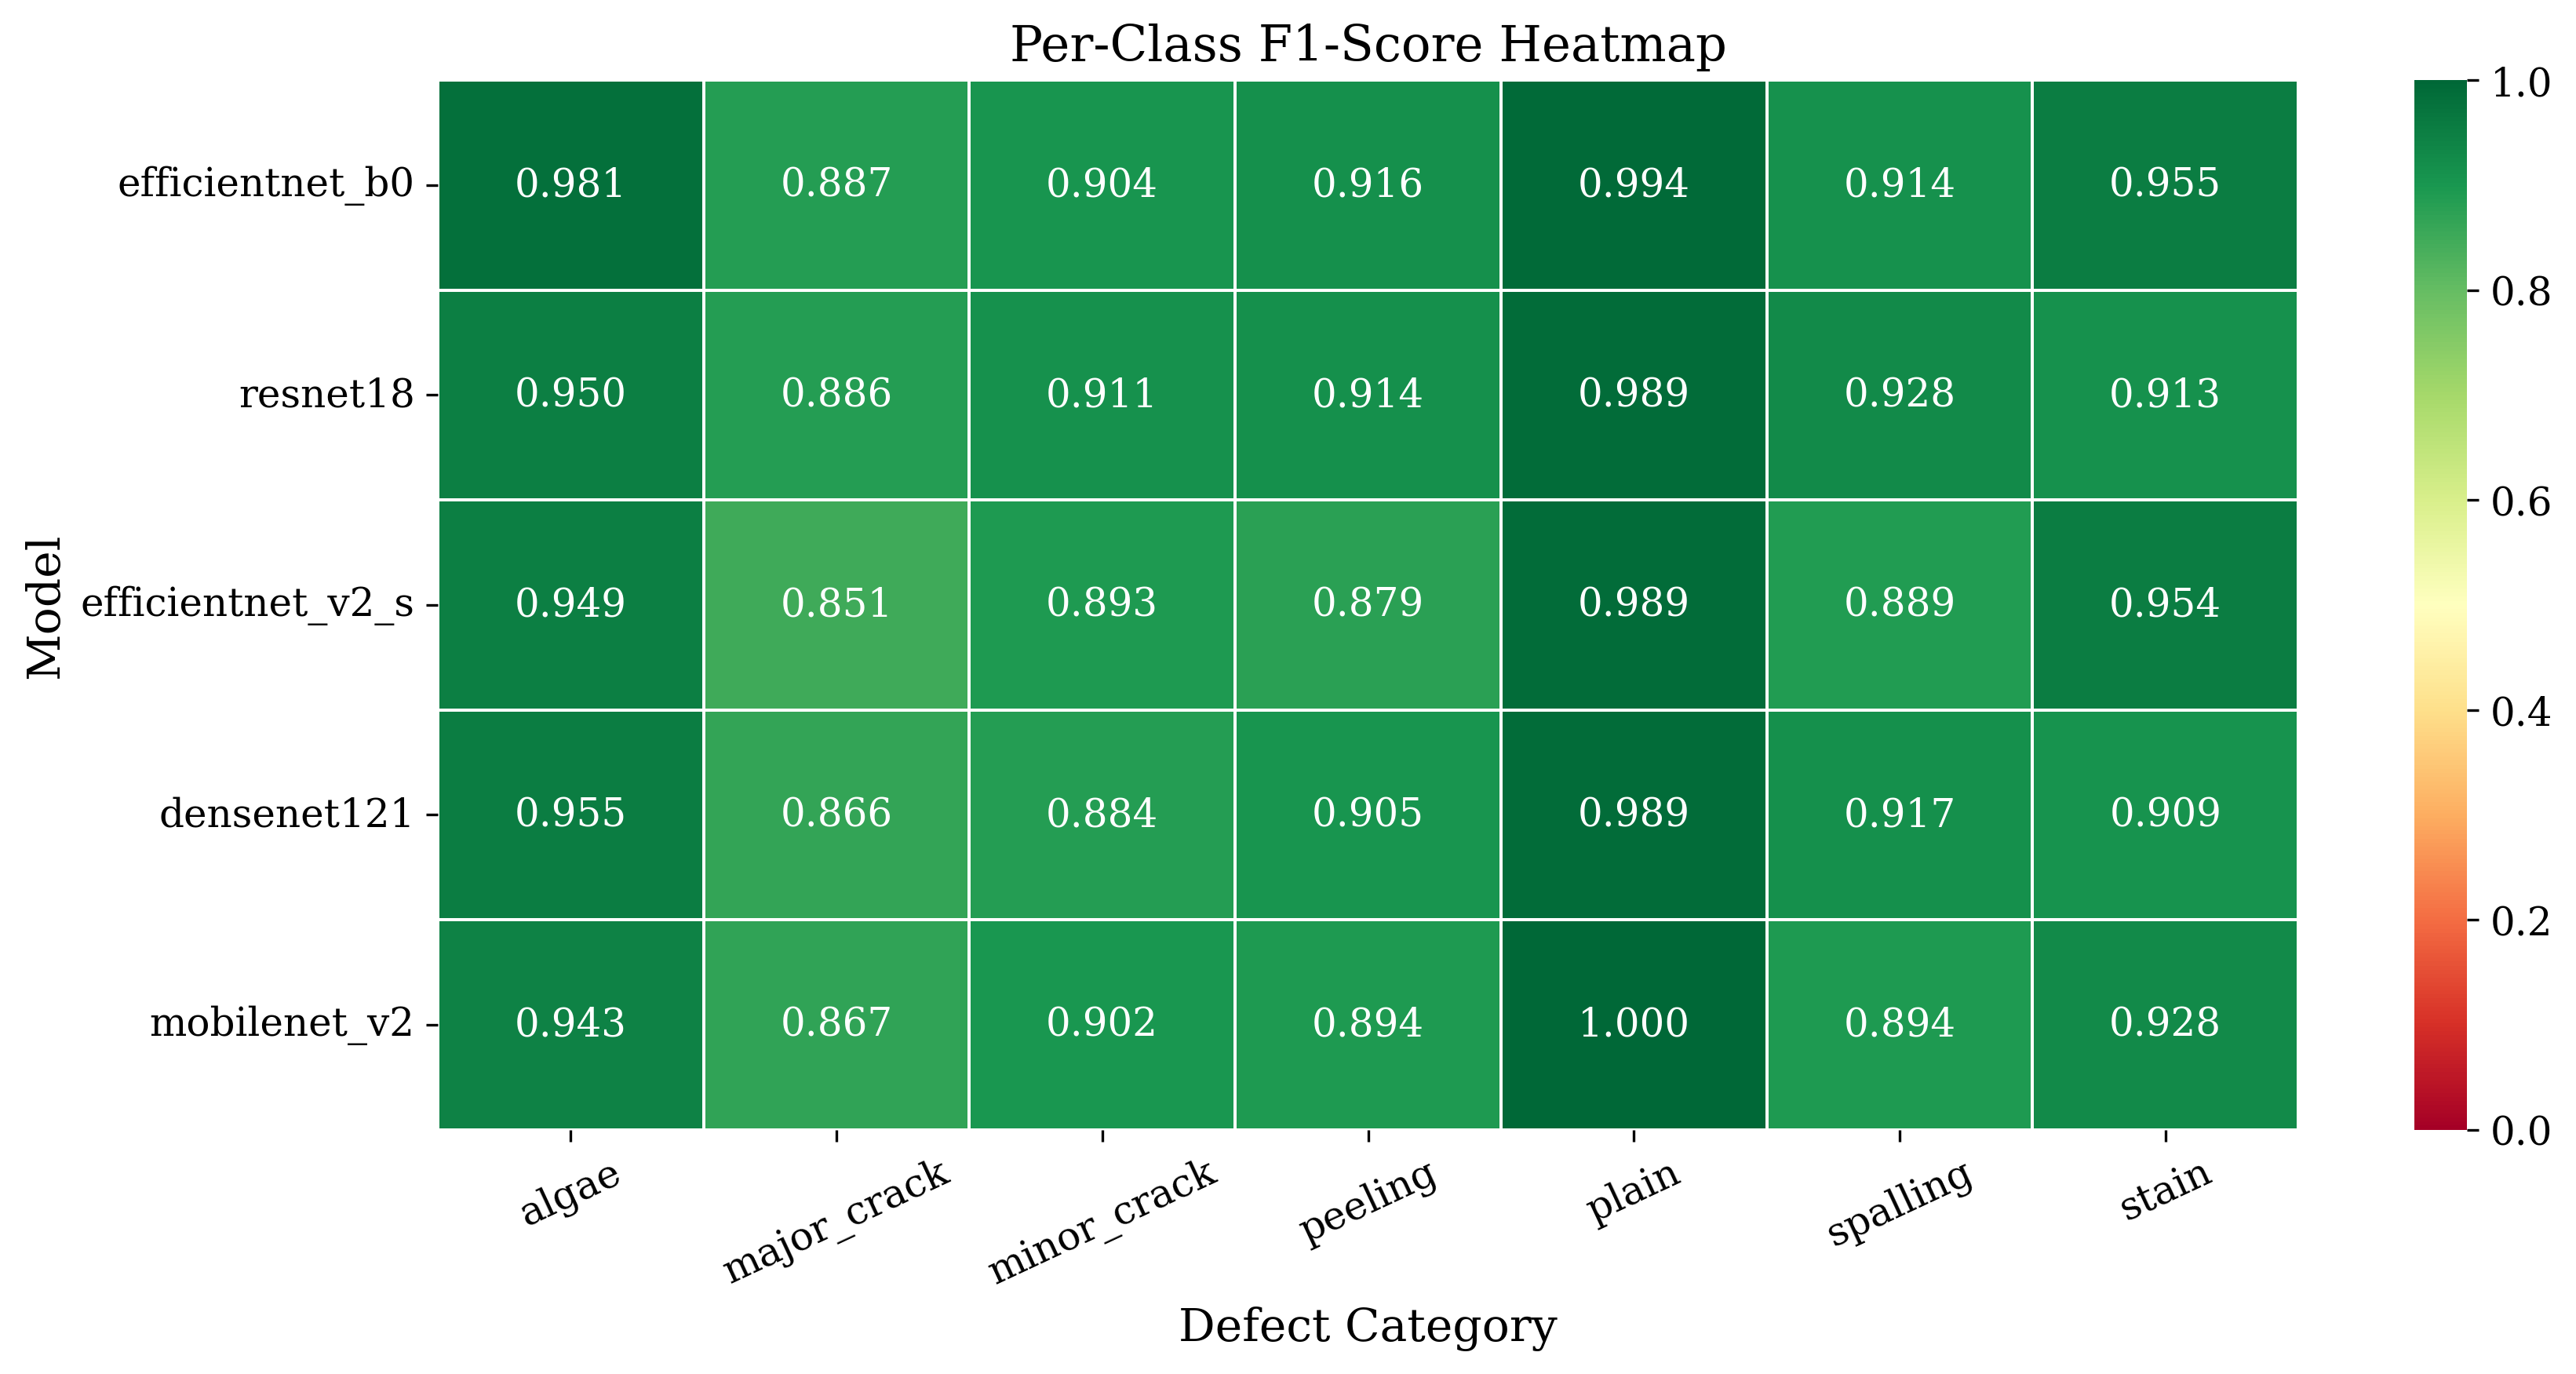

In [ ]:
f1_matrix, model_labels = [], []
for model_name, results in all_results.items():
    _, _, f1, _ = precision_recall_fscore_support(
        results['true_labels'], results['predictions'], average=None, zero_division=0)
    f1_matrix.append(f1); model_labels.append(model_name)

f1_df = pd.DataFrame(f1_matrix, index=model_labels, columns=class_names)
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(f1_df, annot=True, fmt='.3f', cmap='RdYlGn', ax=ax, vmin=0, vmax=1, linewidths=0.5)
ax.set_xlabel('Defect Category'); ax.set_ylabel('Model')
ax.set_title('Per-Class F1-Score Heatmap'); ax.tick_params(axis='x', rotation=25)
plt.tight_layout()
plt.savefig('fig14_f1_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

### Radar Chart (multi-metric per model)

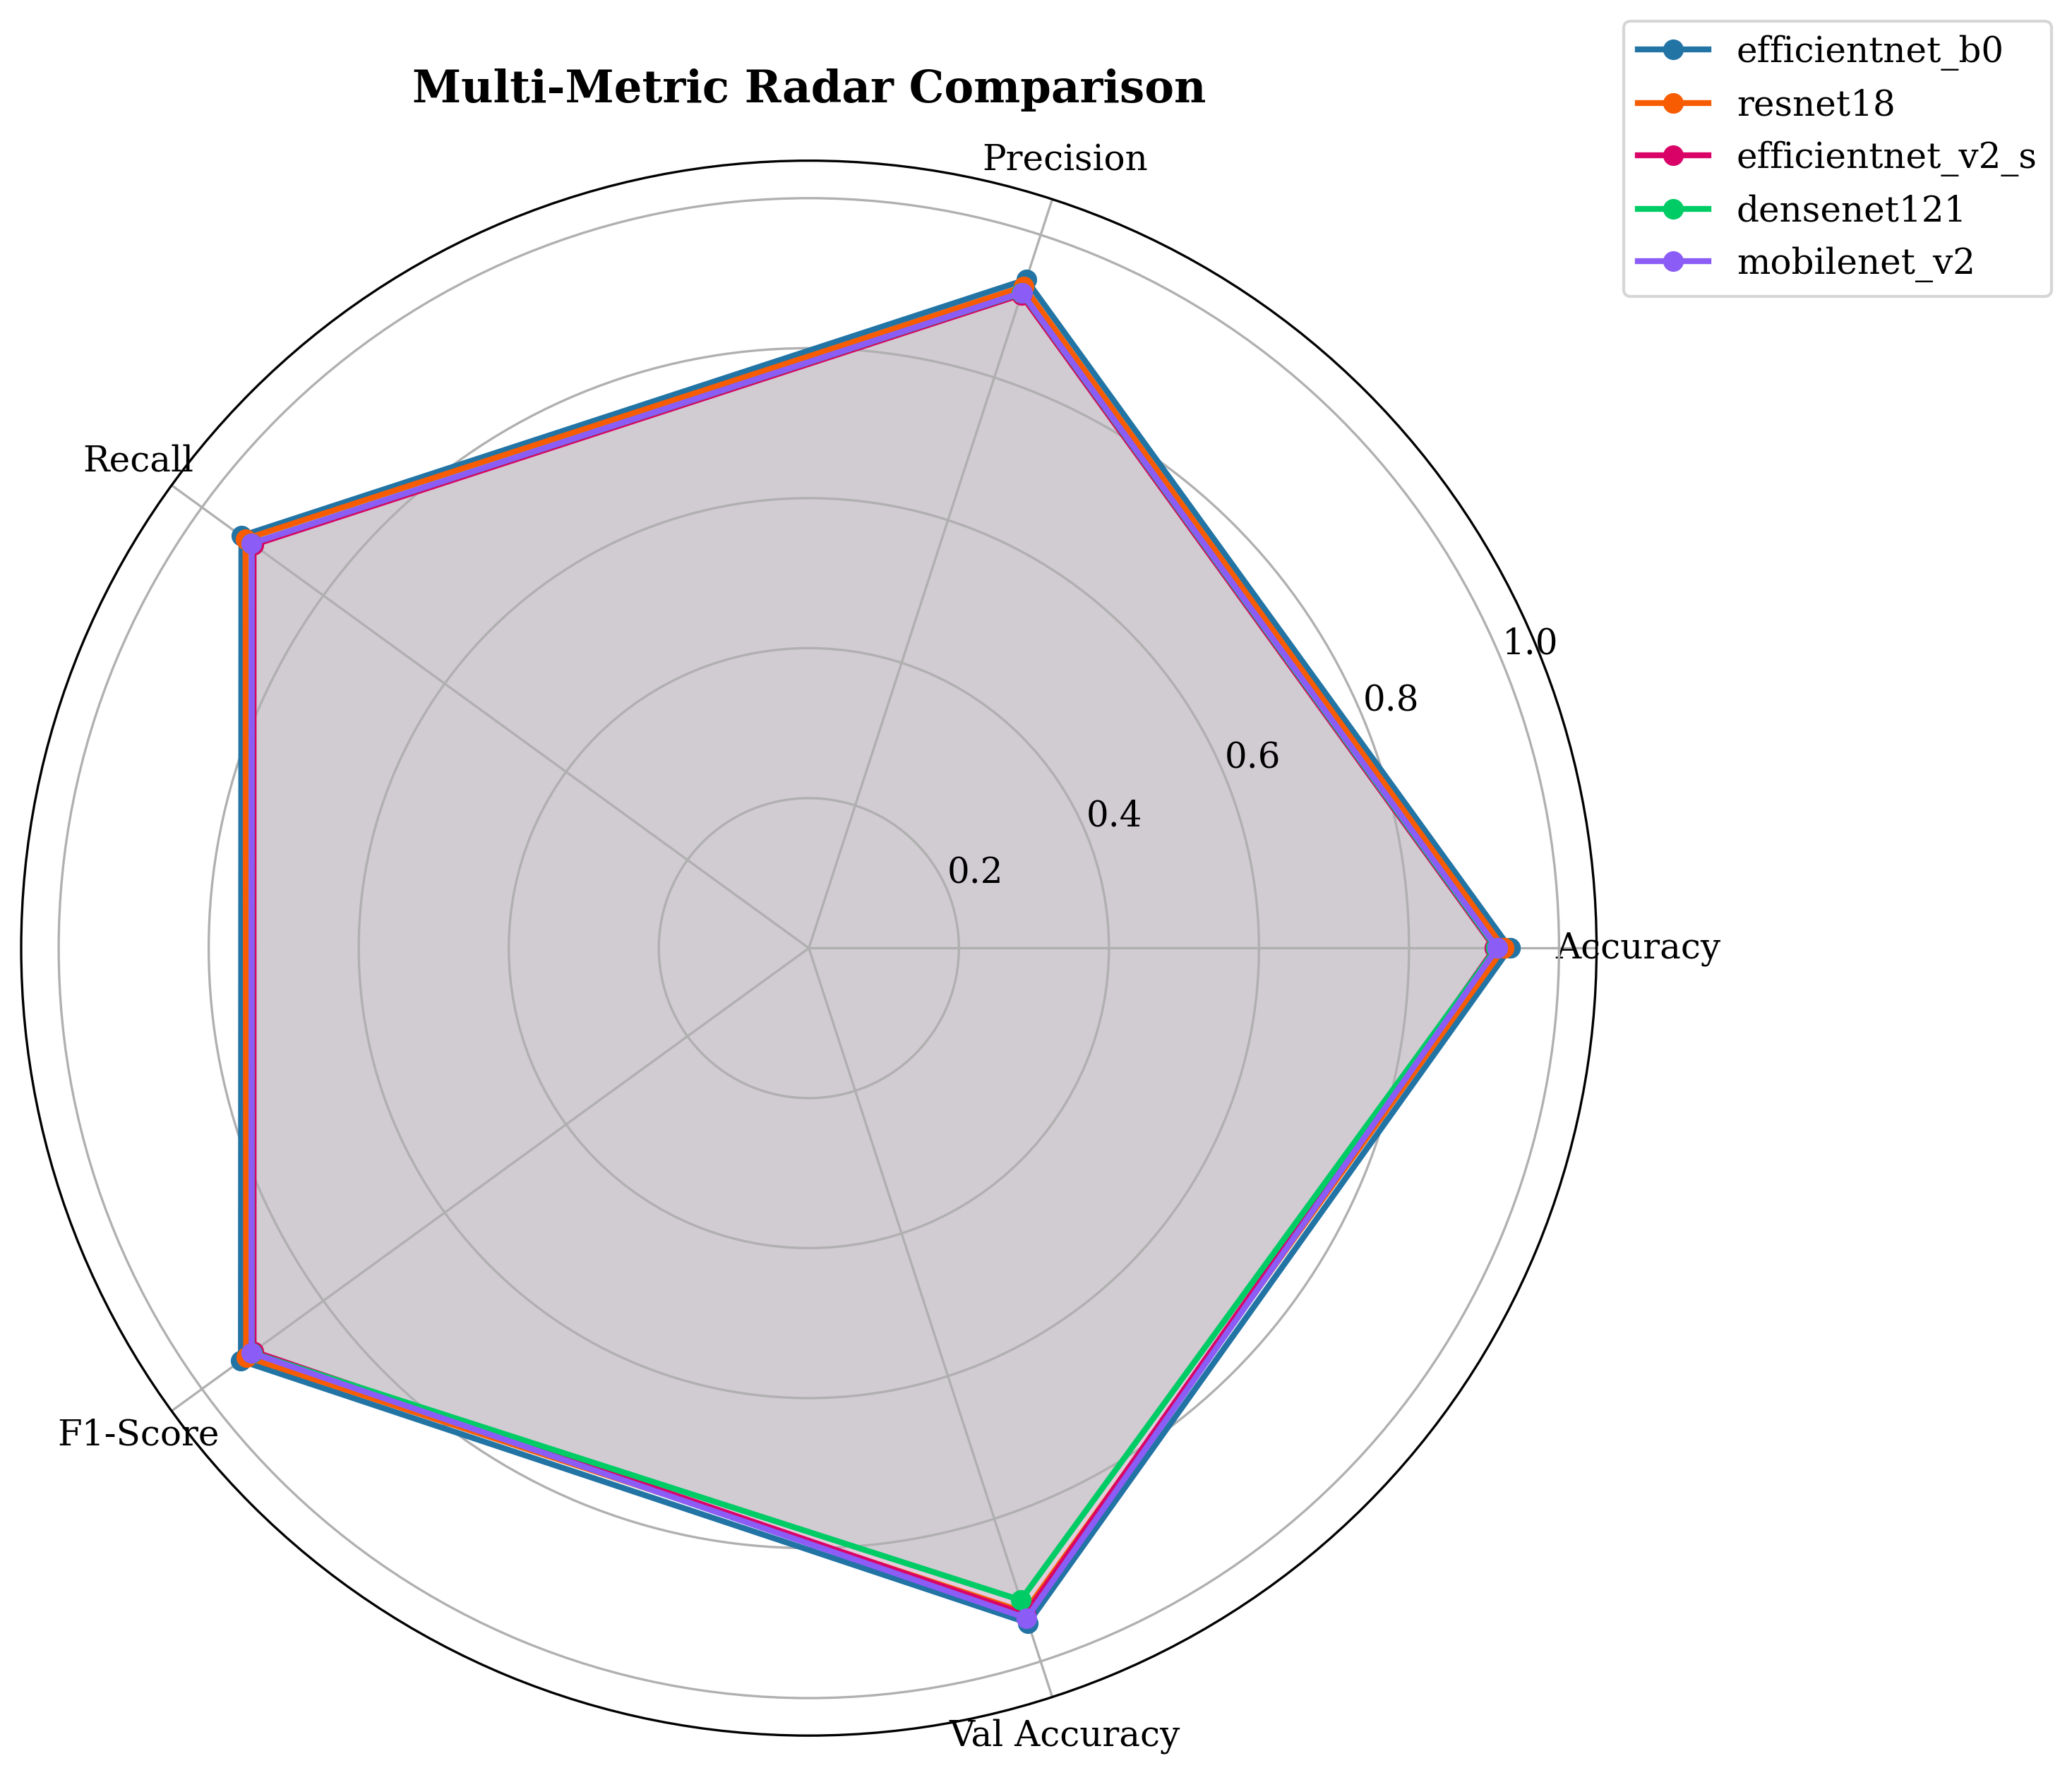

In [ ]:
radar_data = {}
for model_name, results in all_results.items():
    prec, rec, f1, _ = precision_recall_fscore_support(
        results['true_labels'], results['predictions'], average='macro', zero_division=0)
    radar_data[model_name] = {
        'Accuracy': results['test_acc']/100, 'Precision': prec,
        'Recall': rec, 'F1-Score': f1, 'Val Accuracy': results['best_val_acc']/100}

categories = list(list(radar_data.values())[0].keys())
N = len(categories)
angles = [n/float(N)*2*np.pi for n in range(N)] + [0]

fig, ax = plt.subplots(figsize=(10, 10), subplot_kw=dict(polar=True))
for idx, (model_name, metrics) in enumerate(radar_data.items()):
    values = list(metrics.values()) + [list(metrics.values())[0]]
    ax.plot(angles, values, 'o-', linewidth=2, color=COLORS[idx], label=model_name, markersize=6)
    ax.fill(angles, values, alpha=0.08, color=COLORS[idx])

ax.set_xticks(angles[:-1]); ax.set_xticklabels(categories, fontsize=12)
ax.set_ylim(0, 1.05); ax.set_title('Multi-Metric Radar Comparison', fontsize=15, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.tight_layout()
plt.savefig('fig15_radar_chart.png', dpi=300, bbox_inches='tight')
plt.show()

###Overfitting Gap Analysis

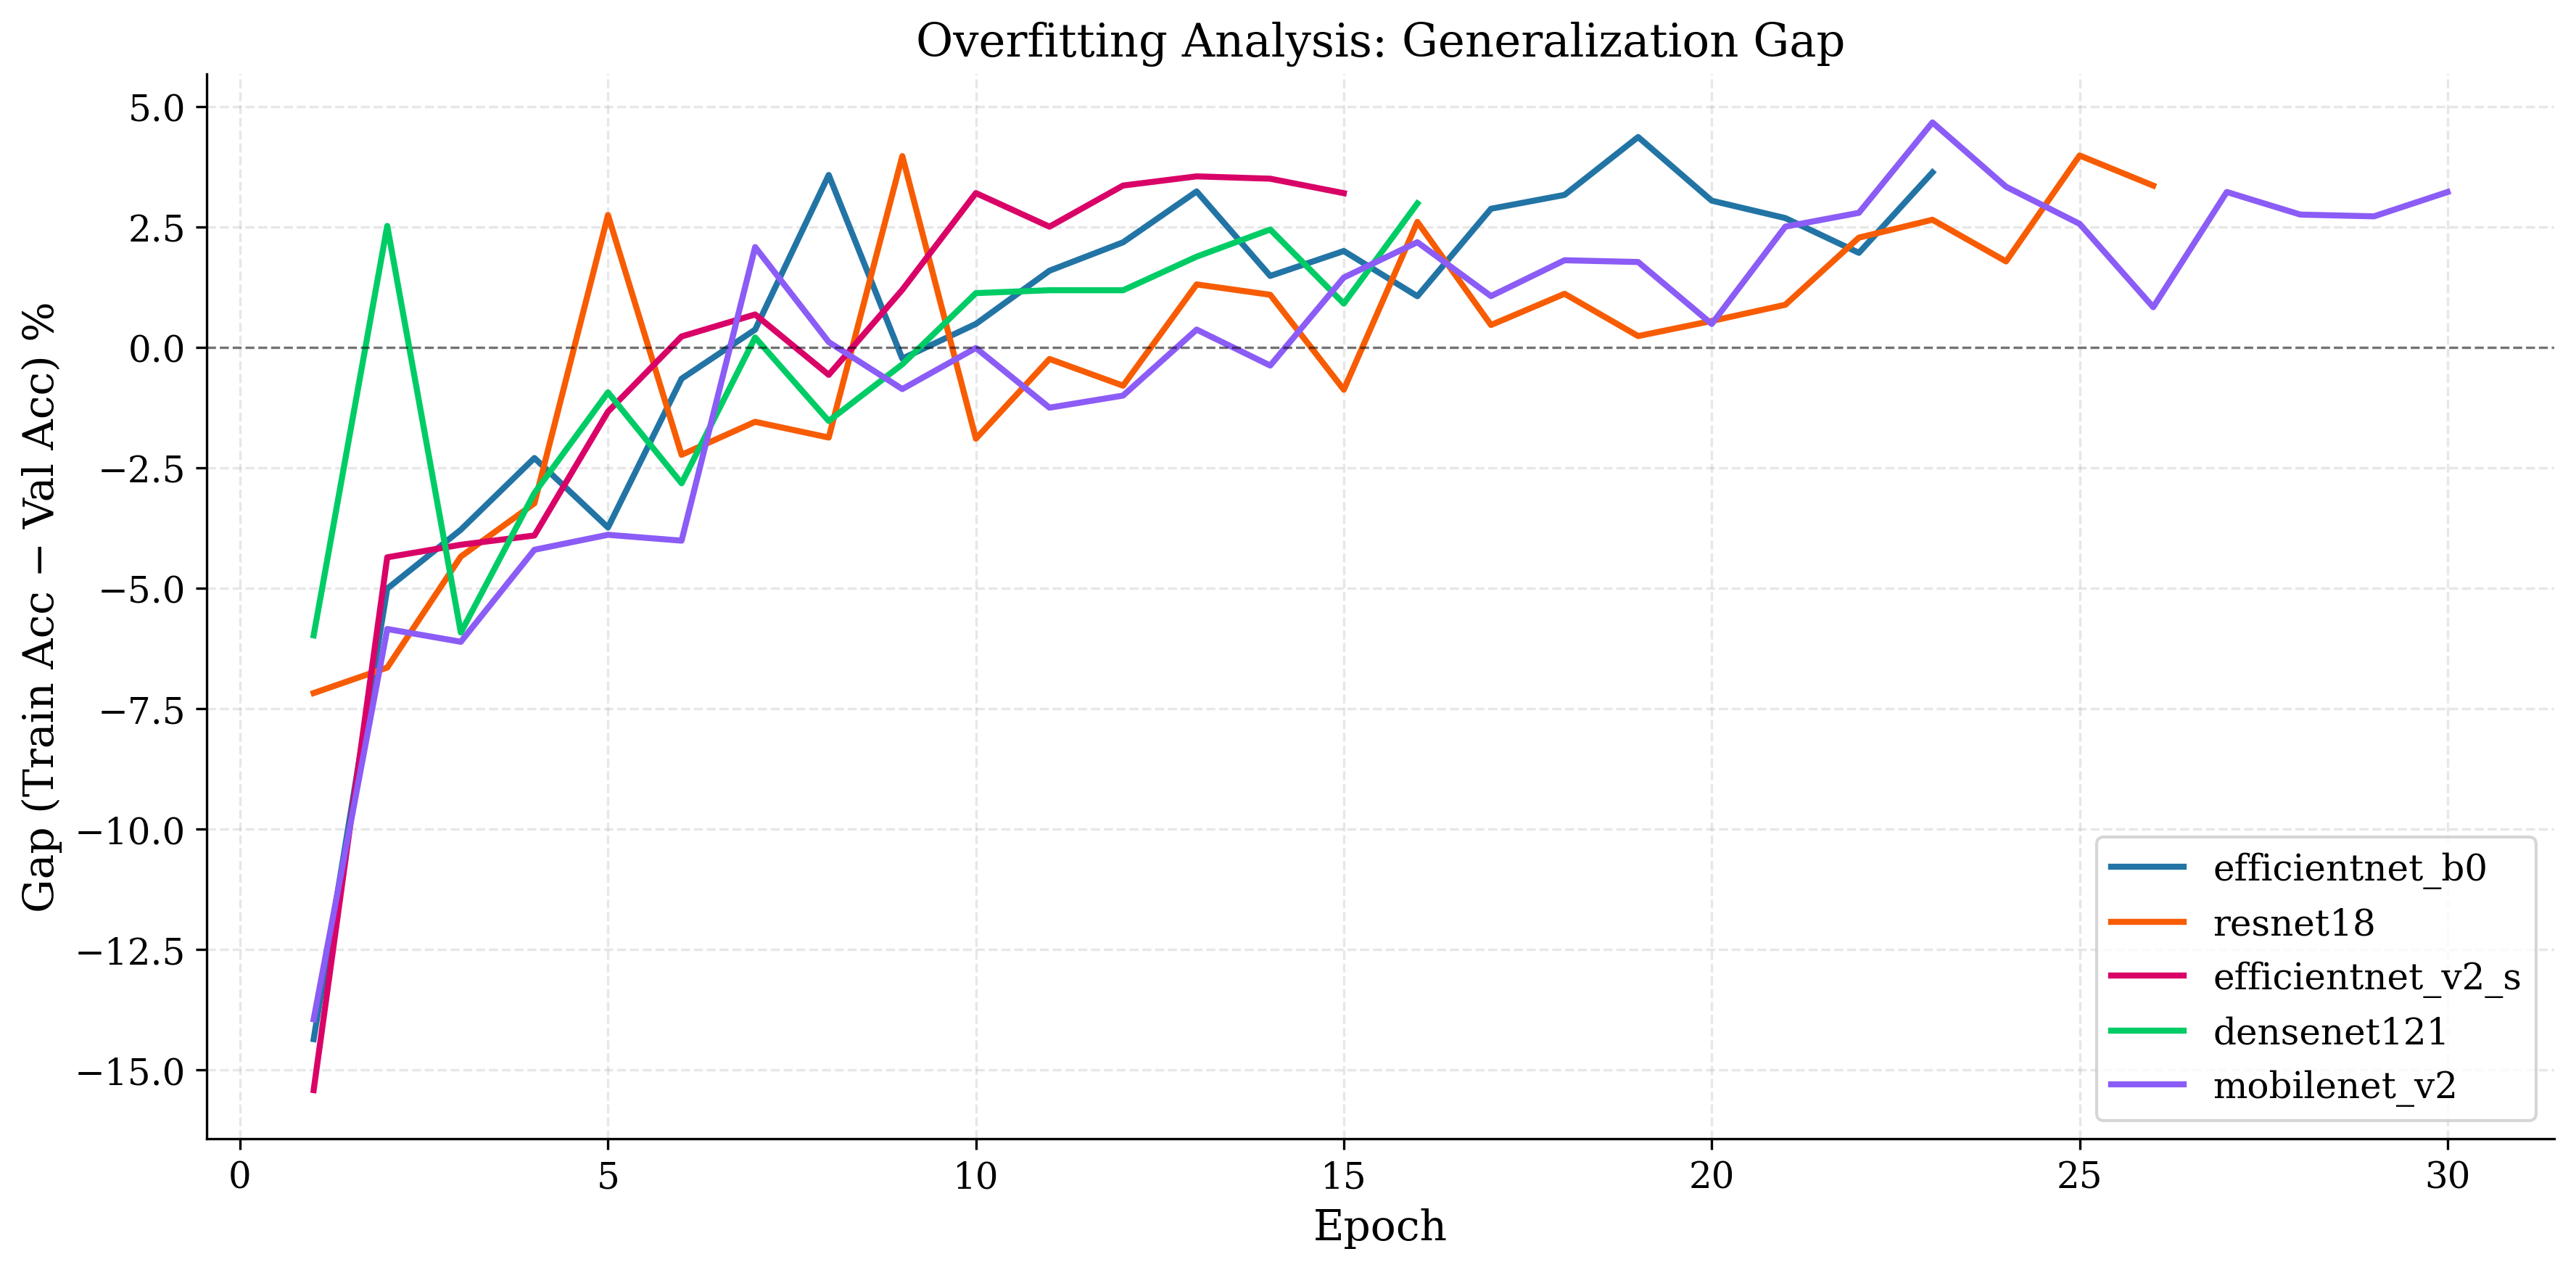

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
for idx, (model_name, results) in enumerate(all_results.items()):
    epochs = range(1, len(results['history']['train_acc']) + 1)
    gap = [t - v for t, v in zip(results['history']['train_acc'], results['history']['val_acc'])]
    ax.plot(epochs, gap, '-', color=COLORS[idx], linewidth=2, label=model_name)

ax.axhline(y=0, color='black', linewidth=0.8, linestyle='--', alpha=0.5)
ax.set_xlabel('Epoch'); ax.set_ylabel('Gap (Train Acc − Val Acc) %')
ax.set_title('Overfitting Analysis: Generalization Gap'); ax.legend(); ax.grid(True, alpha=0.3, linestyle='--')
plt.tight_layout()
plt.savefig('fig16_overfitting_gap.png', dpi=300, bbox_inches='tight')
plt.show()

###Classification Report + Full Comparison Table (CSV + LaTeX)

In [ ]:
# Classification report for best model
best_res = all_results[best_model_name]
report = classification_report(best_res['true_labels'], best_res['predictions'],
                                target_names=class_names, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose().round(4)
report_df.to_csv('table1_classification_report.csv')
print(f"\nClassification Report — {best_model_name}:\n")
print(report_df.to_string())

# Full comparison table
full_comp = []
for model_name, results in all_results.items():
    p, r, f, _ = precision_recall_fscore_support(results['true_labels'], results['predictions'], average='macro', zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(results['true_labels'], results['predictions'], average='weighted', zero_division=0)
    full_comp.append({
        'Model': model_name, 'Params (M)': round(results['total_params']/1e6, 2),
        'Val Acc': round(results['best_val_acc'], 2), 'Test Acc': round(results['test_acc'], 2),
        'Macro P': round(p, 4), 'Macro R': round(r, 4), 'Macro F1': round(f, 4),
        'Wt P': round(pw, 4), 'Wt R': round(rw, 4), 'Wt F1': round(fw, 4),
        'Epochs': len(results['history']['val_acc']),
        'Best Ep': int(np.argmax(results['history']['val_acc'])+1)
    })

full_df = pd.DataFrame(full_comp).sort_values('Test Acc', ascending=False)
full_df.to_csv('table2_full_comparison.csv', index=False)
full_df.to_latex('table2_full_comparison.tex', index=False, float_format="%.4f",
                  caption="Comprehensive Model Comparison", label="tab:comparison")
print(f"\n{full_df.to_string(index=False)}")

# Per-class F1 table
f1_df.to_csv('table3_per_class_f1.csv')
f1_df.round(4).to_latex('table3_per_class_f1.tex', float_format="%.4f",
                          caption="Per-Class F1-Score", label="tab:f1")
print("\n✓ All tables saved (CSV + LaTeX)")


Classification Report — efficientnet_b0:

              precision  recall  f1-score   support
algae            0.9747  0.9872    0.9809   78.0000
major_crack      0.8738  0.9000    0.8867  100.0000
minor_crack      0.9140  0.8947    0.9043   95.0000
peeling          0.9524  0.8824    0.9160   68.0000
plain            0.9885  1.0000    0.9942   86.0000
spalling         0.8916  0.9367    0.9136   79.0000
stain            0.9659  0.9444    0.9551   90.0000
accuracy         0.9346  0.9346    0.9346    0.9346
macro avg        0.9373  0.9351    0.9358  596.0000
weighted avg     0.9352  0.9346    0.9346  596.0000

            Model  Params (M)  Val Acc  Test Acc  Macro P  Macro R  Macro F1   Wt P   Wt R  Wt F1  Epochs  Best Ep
  efficientnet_b0        4.02    94.61     93.46   0.9373   0.9351    0.9358 0.9352 0.9346 0.9346      23       16
         resnet18       11.18    93.10     92.62   0.9274   0.9283    0.9273 0.9269 0.9262 0.9260      26       19
     mobilenet_v2        2.23    93.94 